# Zimbabwe maize yield atlas

The yield map plots crop cuts at their recorded coordinates, with close-ups of Guruve and Shurugwi. Circles show individual locations. If several fields share a recorded coordinate, the circle shows their mean. The next maps compare measured and predicted yield, follow vegetation through the growing season and put three years of weather in context. Each map pairs a description with a full-resolution download.

The national overview, linked close-ups and harvest-year panels adapt the layout of Fig. 5 in Jin et al. (2019) to Zimbabwe's crop-cut data. The grayscale landscape comes from the 2016 EOX Sentinel-2 cloudless mosaic. The year labels on the colored layers identify the observations used for yield, vegetation or weather. [Jin et al.](https://doi.org/10.1016/j.rse.2019.04.016) · [EOX imagery](https://maps.eox.at/)

[Zimbabwe maps](#zimbabwe-maps) · [Yield distributions](#yield-distributions-across-harvests) · [Satellite and model figures](#satellite-observations-and-model-estimates) · [Weather associations](#how-regional-weather-and-measured-yield-vary-together) · [Existing figure gallery](#repository-figure-gallery)

**Read or run the atlas.** All eight Zimbabwe figures and all 106 gallery previews have saved outputs and explanations in this notebook. The map captions link to the full-resolution PNGs. To regenerate the figures, run the cells in order from a checkout containing the gallery source revision. [Full-resolution figures](../results/visual_atlas/) · [Environment requirements](../requirements.txt).

In [1]:
from pathlib import Path
import sys
from io import BytesIO
from PIL import Image as PILImage

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
ROOT = next(p for p in (here, *here.parents) if (p / "configs" / "team_database_v2.json").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
OUT = ROOT / "results" / "visual_atlas"
OUT.mkdir(parents=True, exist_ok=True)
weather_dir = ROOT / "data" / "processed" / "zimbabwe_weather_v2"
fields = pd.read_parquet(weather_dir / "harmonized_labels_weather.parquet")
assert fields.obs_id.is_unique and fields.country_iso3.eq("ZWE").all()
assert np.isfinite(fields.yield_t_ha).all()

def show_file(path):
    display(Image(filename=str(path), width=1000))

def show_map(path, alt):
    # Full-resolution PNGs are linked in the captions. Compact previews travel with the notebook.
    with PILImage.open(path) as source:
        preview = source.convert("RGB")
        preview.thumbnail((1950, 1950), PILImage.Resampling.LANCZOS)
        buffer = BytesIO()
        preview.save(buffer, format="JPEG", quality=88, subsampling=0, optimize=True)
    display(Image(data=buffer.getvalue(), format="jpeg", width=1050, alt=alt))

def export_figure(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    show_file(path)

Matplotlib is building the font cache; this may take a moment.


## Zimbabwe maps

Zimbabwe’s border and the cities of Harare and Bulawayo provide geographic reference. The satellite mosaic supplies the backdrop. The colored layers come from field measurements, held-out predictions, dated vegetation observations or NASA POWER weather cells, as described under each map. [Boundary and city sources](../results/visual_atlas/sources/natural_earth_provenance.json) · [Satellite basemap and reuse terms](../results/visual_atlas/sources/satellite_basemap_provenance.json)

### Measured maize yield from country to field

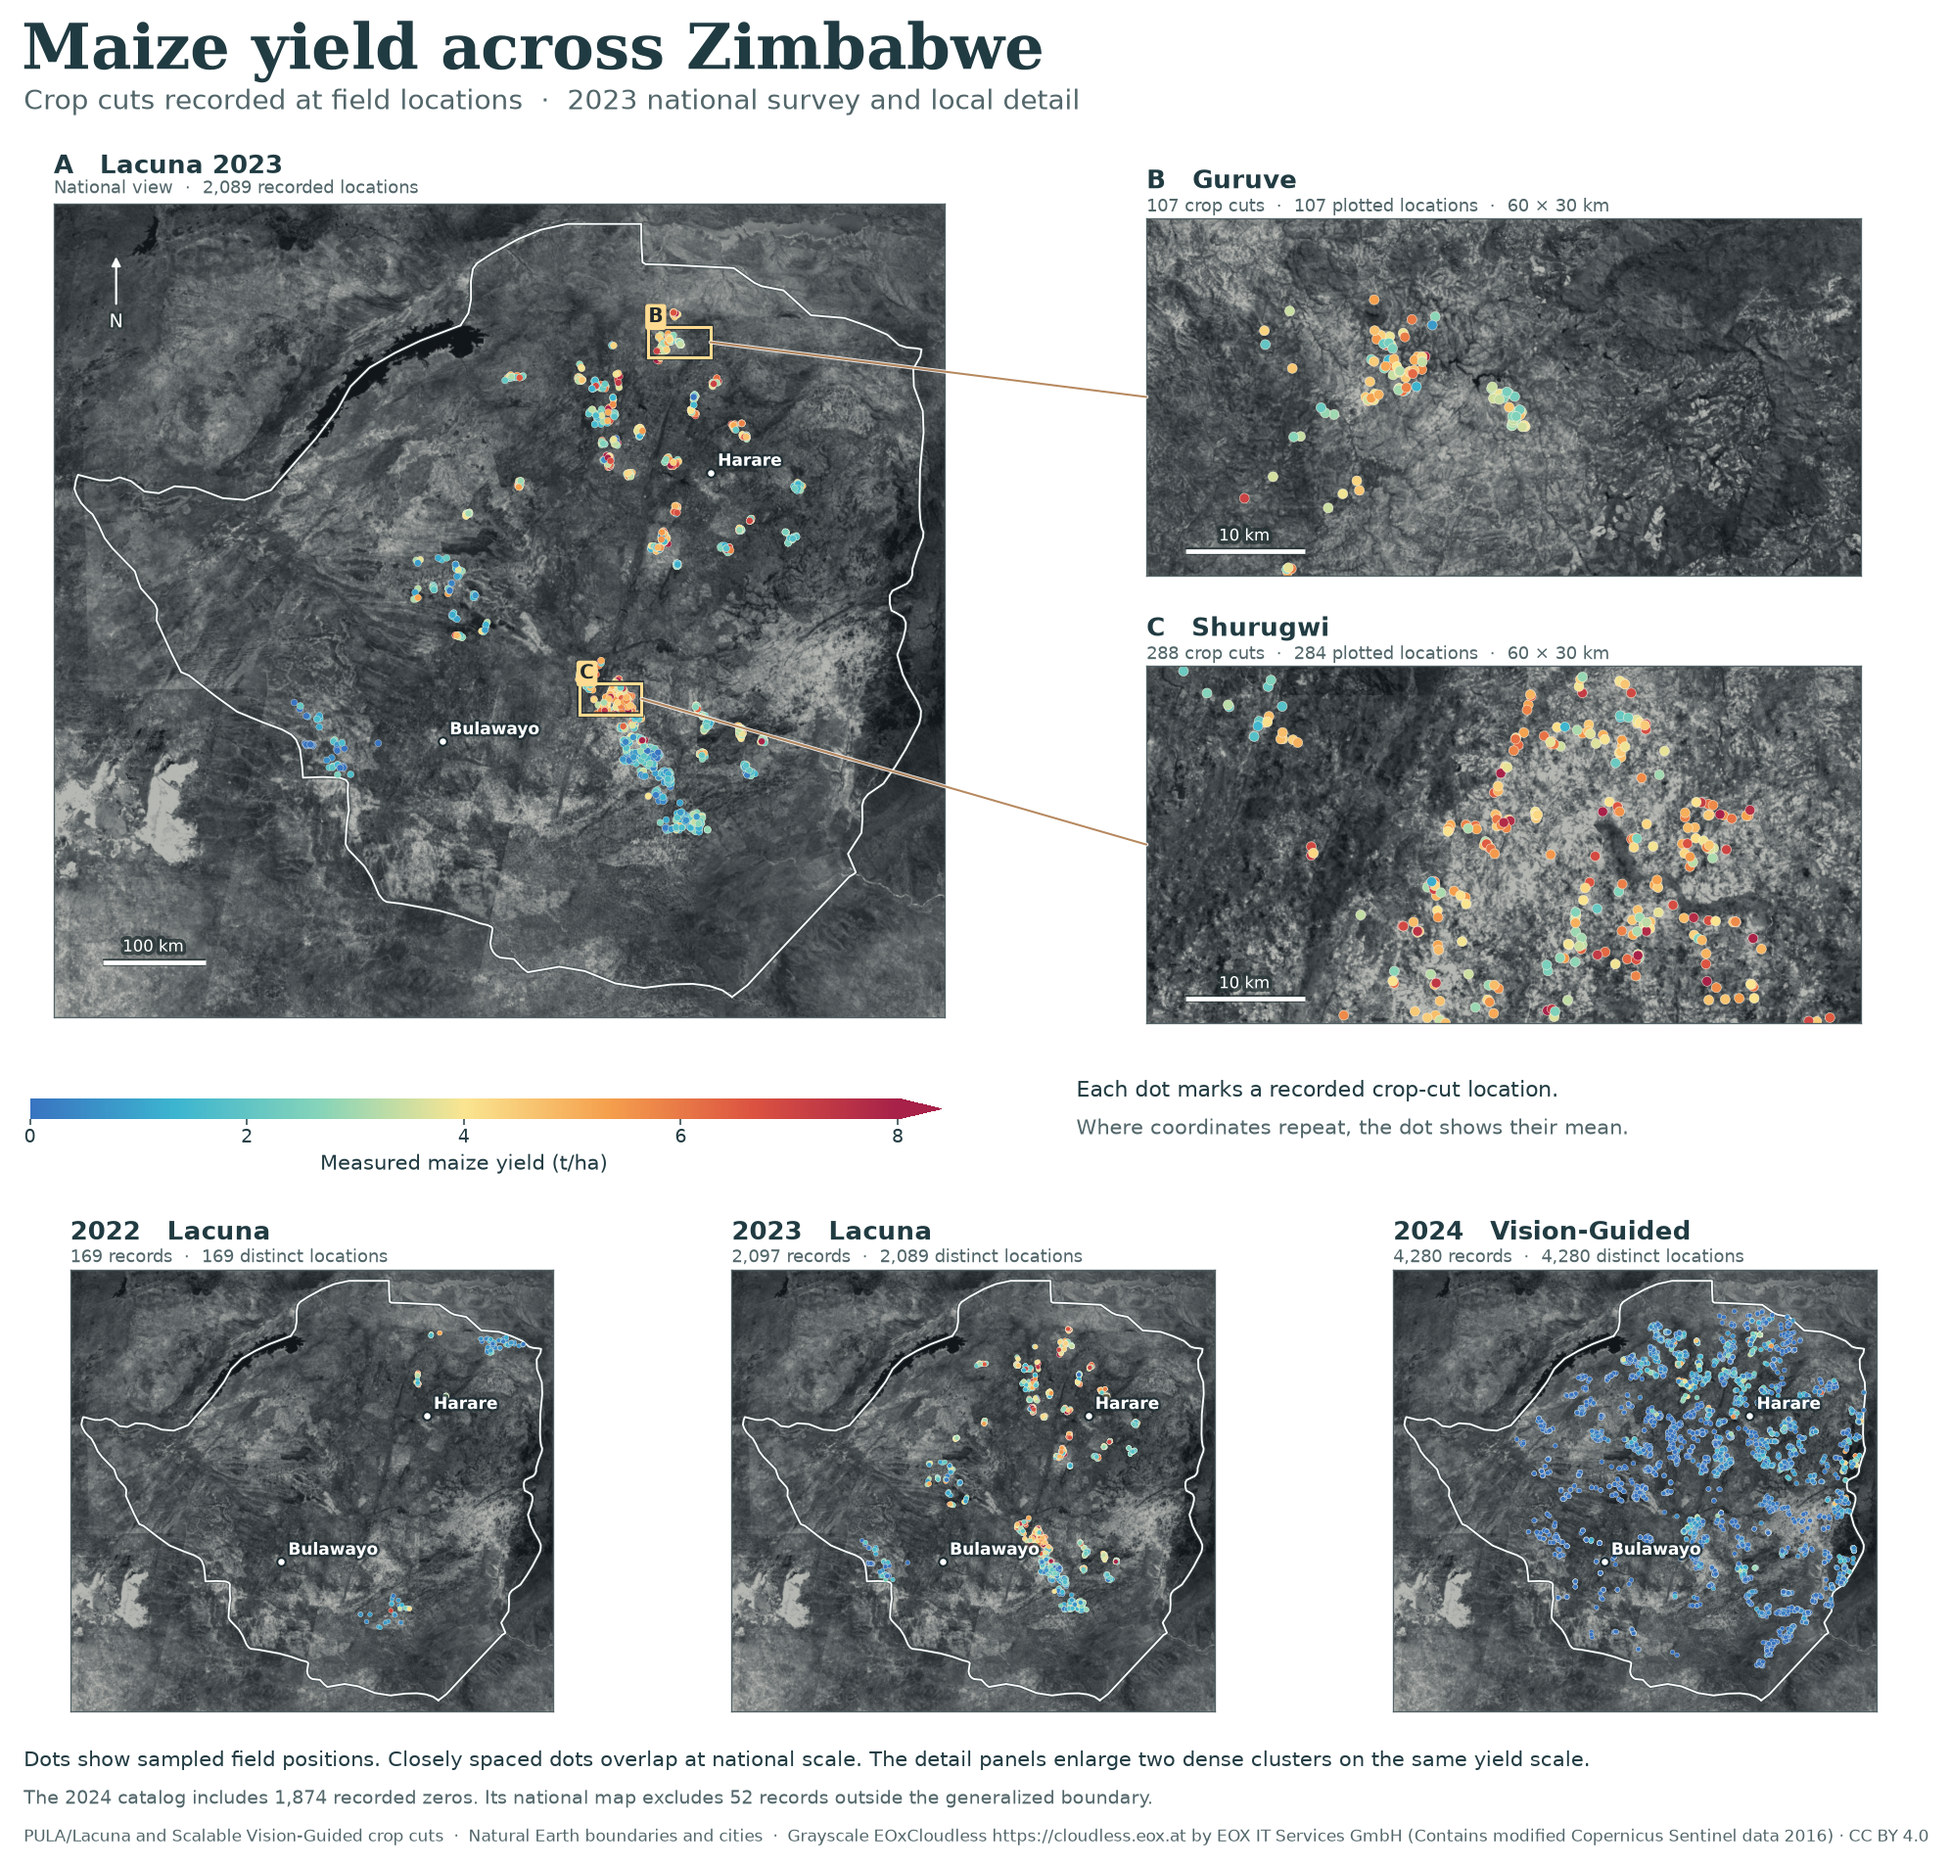

In [2]:
import json
from scripts.paper.atlas_maps import build_maps

map_figures = build_maps(ROOT, OUT)
for figure in map_figures.values():
    plt.close(figure)
map_data = json.loads((OUT / "map_data_summary.json").read_text())
show_map(OUT / "yield_map.png",
         "Measured maize yield on a satellite map of Zimbabwe with Guruve and Shurugwi field close-ups and three harvest-year panels.")

Each circle marks a recorded sampling location. Its color gives measured maize yield in tonnes per hectare (t/ha). Blue marks lower yield and red marks higher yield, with 8 t/ha and above sharing the upper color. Panel A shows all 2,097 screened Lacuna 2023 observations inside the border, at 2,089 locations. Nearby circles can overlap at national scale.

The close-ups show two 60 km × 30 km windows chosen for their concentration of survey records. Guruve contains 107 records at 107 locations. Shurugwi contains 288 records at 284 locations. Only records with identical coordinates are averaged for display. The three annual panels use the same color scale. The 2024 source includes 1,874 recorded zeros in its screened catalog, and 52 of its 4,332 records fall outside the mapped boundary. Different providers sampled different places across these years. [Full-size yield map](../results/visual_atlas/yield_map.png) · [Geographic coverage](../results/visual_atlas/map_data_summary.json).

### Measured yield and prediction error

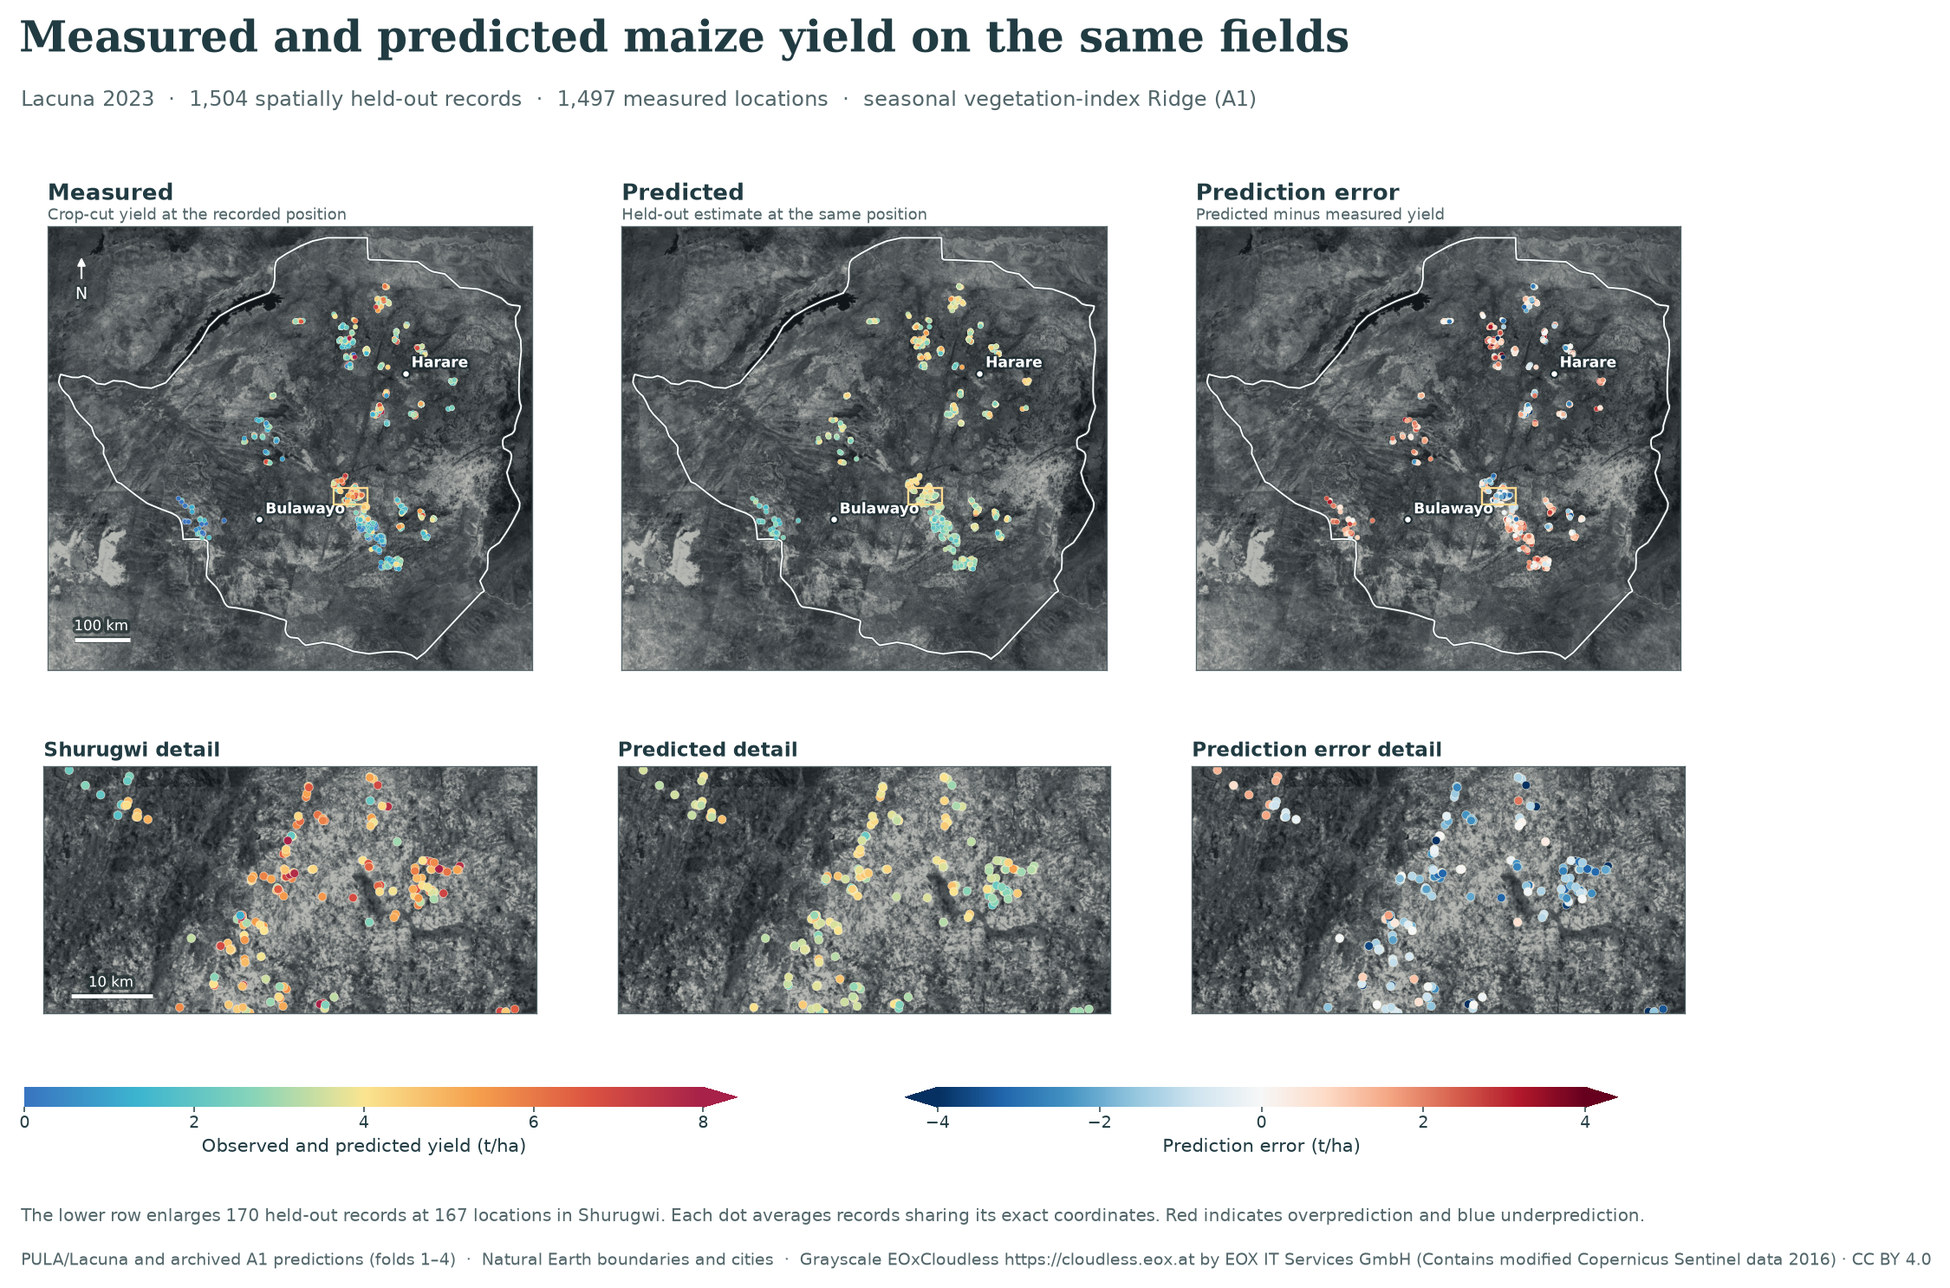

In [3]:
show_map(OUT / "prediction_map.png",
         "Measured yield, held-out Ridge predictions and signed errors at recorded field locations across Zimbabwe and in a Shurugwi close-up.")

Read across each row to compare the measured crop cut, the Ridge model's held-out estimate and the signed error at the same location. Blue error markers indicate underprediction and red markers indicate overprediction, in t/ha. The end colors of the error scale represent values at or beyond ±4 t/ha. The national panels include all 1,504 evaluation fields at 1,497 distinct locations. The lower row enlarges the same Shurugwi window used on the yield map, covering 170 evaluation fields at 167 locations. Exact coordinate repeats are averaged for display. The field-level RMSE of 1.79 t/ha uses all 1,504 predictions. [Full-size prediction map](../results/visual_atlas/prediction_map.png) · [Field predictions](../experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/predictions.csv).

### Where the maize canopy was greener

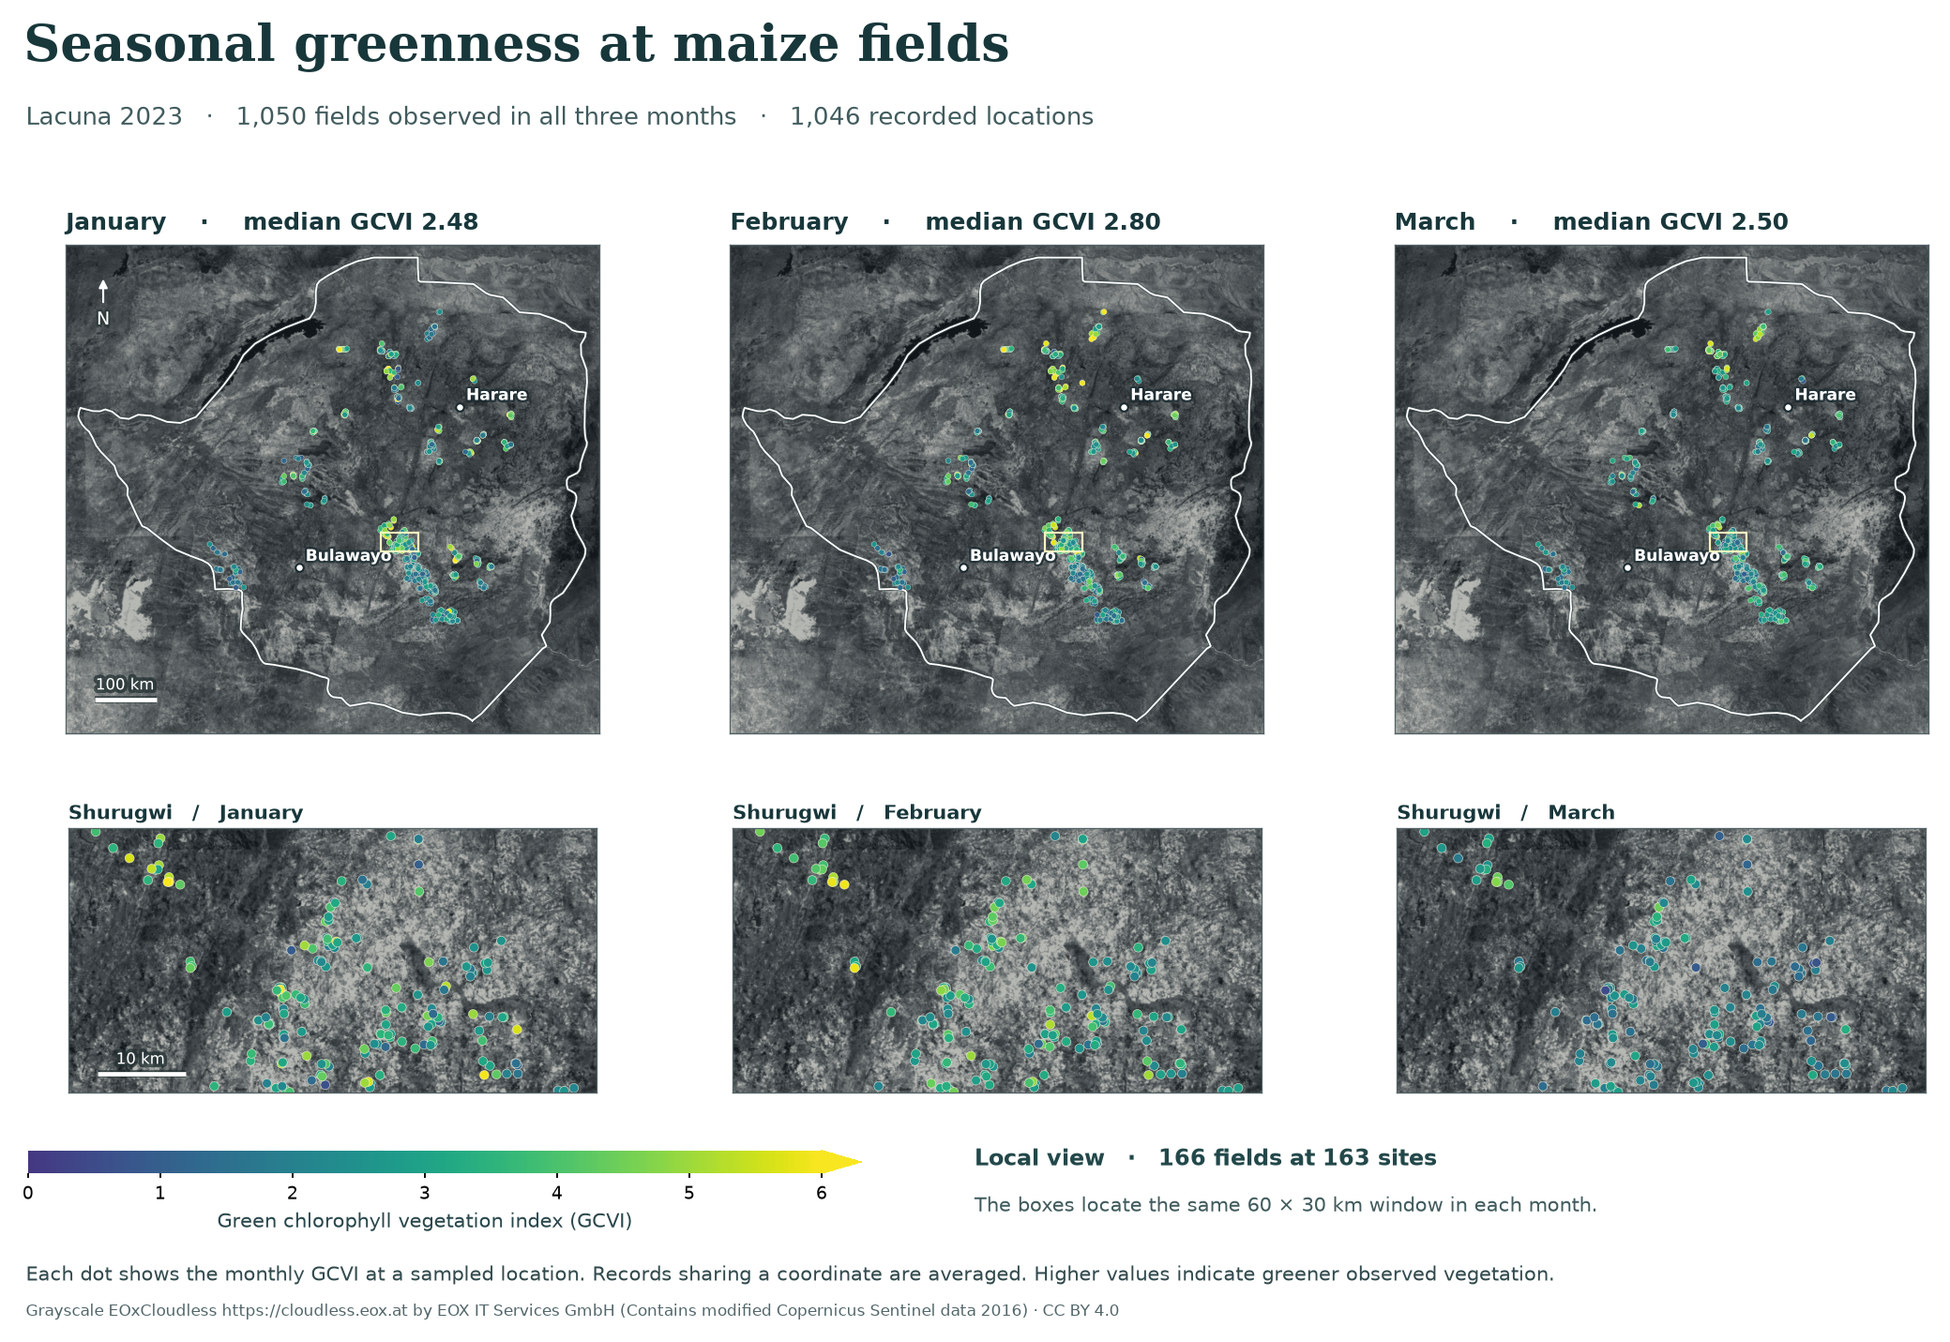

,month,primary_fields,matched_fields,mapped_fields,mapped_locations,median_site_gcvi,closeup_fields,closeup_locations,closeup_median_gcvi
0,2023-01,1880,1050,1050,1046,2.48,166,163,3.08
1,2023-02,1880,1050,1050,1046,2.80,166,163,3.14
2,2023-03,1880,1050,1050,1046,2.50,166,163,2.10


In [4]:
from scripts.paper.atlas_greenness_map import build_greenness_map

gcvi_support = build_greenness_map(ROOT, OUT)
show_map(OUT / "greenness_map.png",
         "January, February and March greenness at 1,046 recorded field locations, with the same Shurugwi close-up in each month.")
display(gcvi_support.round(2))

The top row follows 1,050 Lacuna 2023 fields with clear Sentinel-2 observations in all three months. Exact coordinate repeats give 1,046 plotted locations. Each circle shows the green chlorophyll vegetation index (GCVI) measured at that location. Purple-blue indicates lower greenness and yellow-green indicates higher greenness. Values of 6 and above share the upper color. The median across locations rose from 2.48 in January to 2.80 in February, then fell to 2.50 in March.

The lower row enlarges the same 166 matched fields at 163 locations in Shurugwi. Keeping the locations fixed lets the reader follow changes in canopy greenness over the season. The grayscale landscape is the historical reference mosaic. [Full-size greenness map](../results/visual_atlas/greenness_map.png) · [Monthly imagery and provenance](../data/processed/zimbabwe_midterm_v2/README.md).

### Rainfall and temperature during the rainy season

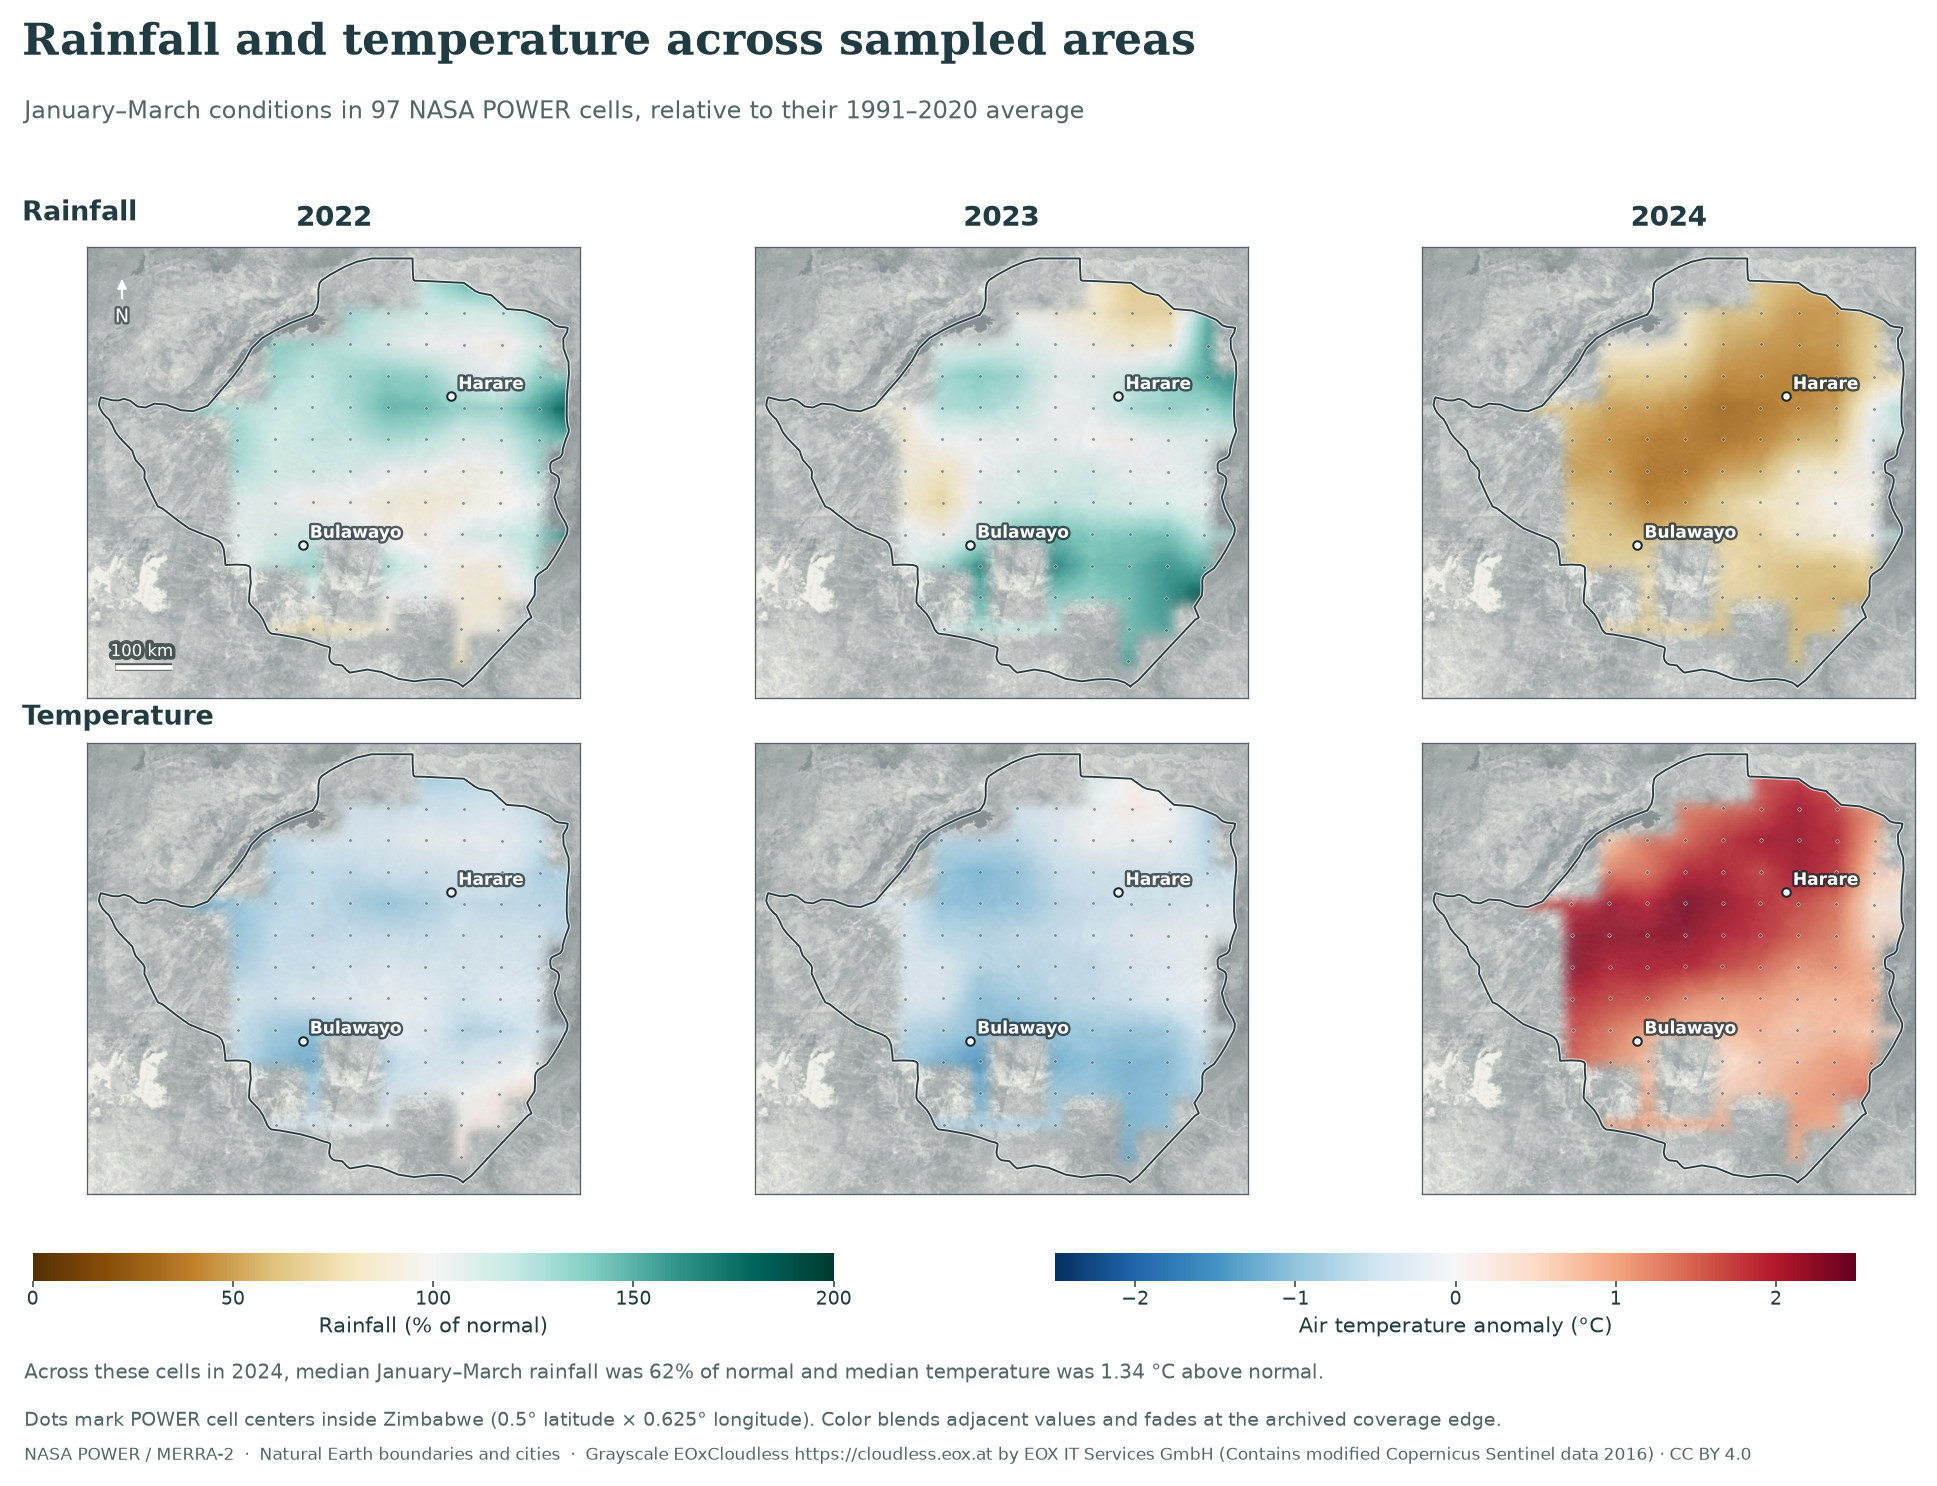

,Median rainfall (% of normal),Median temperature anomaly (°C)
Harvest year,,
2022,113.68,-0.46
2023,110.70,-0.64
2024,62.16,1.34


In [5]:
show_map(OUT / "weather_map.png",
         "January–March rainfall and air-temperature departures for 2022, 2023 and 2024 across the same Zimbabwe weather cells.")
weather_summary = pd.DataFrame({
    int(year): {"Median rainfall (% of normal)": v["rain_pct"]["median"],
                "Median temperature anomaly (°C)": v["temp_anomaly"]["median"]}
    for year, v in map_data["weather"]["years"].items()
}).T.rename_axis("Harvest year")
display(weather_summary.round(2))

The columns compare January–March conditions in three harvest years. Brown means rainfall fell below the local 1991–2020 normal and teal means it was above normal. In the temperature row, red marks warmer and blue marks cooler conditions. NASA POWER supplies one estimate per 0.5° latitude × 0.625° longitude cell. The map blends neighboring cell-center values for display within the archived footprint. Dots mark the 86 source centers inside the border. The other 11 source cells overlap Zimbabwe at their edges. The original grid sets the detail at which these conditions can be interpreted.

Across the same 97 archived cells, median rainfall was 114% of normal in 2022, 111% in 2023 and 62% in 2024. Median temperature departures were −0.46, −0.64 and +1.34 °C. These summaries use the original cell values. [Full-size weather map](../results/visual_atlas/weather_map.png) · [Weather source and processing](../data/processed/zimbabwe_weather_v2/README.md).

## Yield distributions across harvests

Following the distribution comparison in Jin et al. Fig. 6a, each curve shows the fraction of recorded fields with yield at or below a given value. Every field contributes one observation. The solid lines use the screened catalog. Dashed lines apply the project's v2 primary-label rule before satellite coverage and spatial splits. The 2024 sensitivity is particularly important because 1,874 of its 4,332 records report zero. Their measurement status is uncertain and v2 excludes them from training. The 2022 panel contains ground observations only. [Input records](../data/processed/zimbabwe_weather_v2/harmonized_labels_weather.parquet).

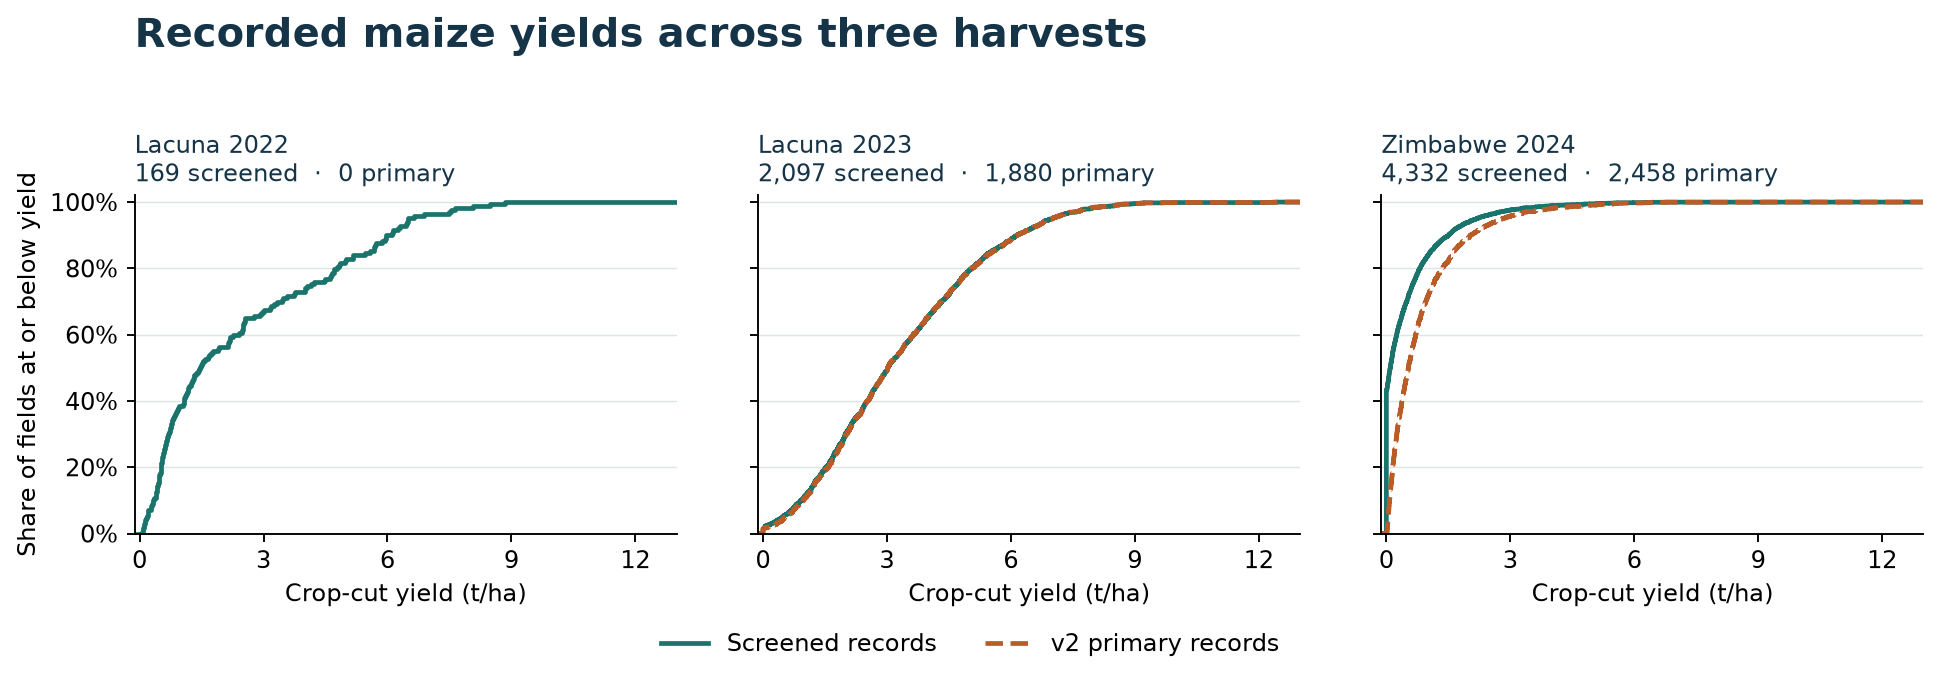

,fields,q05,median,q95
season_year,,,,
2022,169,0.18,1.46,6.50
2023,2097,0.48,3.02,7.00
2024,4332,0.00,0.09,2.18


In [6]:
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

season_names = {2022: "Lacuna 2022", 2023: "Lacuna 2023", 2024: "Zimbabwe 2024"}
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9), sharex=True, sharey=True)
fig.subplots_adjust(left=.07, right=.985, top=.72, bottom=.21, wspace=.15)
fig.suptitle("Recorded maize yields across three harvests", x=.07, y=.99, ha="left",
             fontsize=17, fontweight="bold", color="#163447")
for ax, (year, label) in zip(axes, season_names.items()):
    sample = fields.loc[fields.season_year.eq(year)]
    for pool, color, style in [(sample, "#1A746B", "-"),
                               (sample.loc[sample.include_primary], "#B95C28", "--")]:
        if pool.empty:
            continue
        y, counts = np.unique(pool.yield_t_ha, return_counts=True)
        ax.step(np.r_[-.12, y, 13], np.r_[0, counts.cumsum()/counts.sum(), 1],
                where="post", color=color, linestyle=style, linewidth=2)
    ax.set_title(f"{label}\n{len(sample):,} screened  ·  {sample.include_primary.sum():,} primary",
                 loc="left", fontsize=10, color="#163447")
    ax.grid(axis="y", color="#DDE5E6", linewidth=.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set(xlim=(-.12, 13), ylim=(0, 1.02), xticks=[0, 3, 6, 9, 12], xlabel="Crop-cut yield (t/ha)")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Share of fields at or below yield")
fig.legend([Line2D([], [], color="#1A746B", lw=2), Line2D([], [], color="#B95C28", ls="--", lw=2)],
           ["Screened records", "v2 primary records"], loc="lower center", ncol=2, frameon=False)
export_figure(fig, "yield_distributions.png")

summary = fields.groupby("season_year").yield_t_ha.agg(
    fields="size", q05=lambda s: s.quantile(.05), median="median", q95=lambda s: s.quantile(.95))
display(summary.round(2))

The median recorded yield was 3.02 t/ha for Lacuna 2023 and 0.09 t/ha for the screened 2024 source. The two providers sampled different fields and used different crop-cut protocols. The solid and dashed curves show how sample selection changes the 2024 comparison. [Full-size yield distributions](../results/visual_atlas/yield_distributions.png).

## Satellite observations and model estimates

### Seasonal greenness

Jin et al. used the seasonal course of GCVI, the green chlorophyll vegetation index, in their yield analysis (§4.1.2). We group 1,880 Lacuna 2023 fields by measured harvest yield and show the observed monthly median and interquartile range of GCVI in each group. The count below each month is the number of fields with a usable observation. October and November are gaps. These curves use the original imagery preserved in the corrected v2 handoff table. [Monthly imagery and provenance](../data/processed/zimbabwe_midterm_v2/README.md).

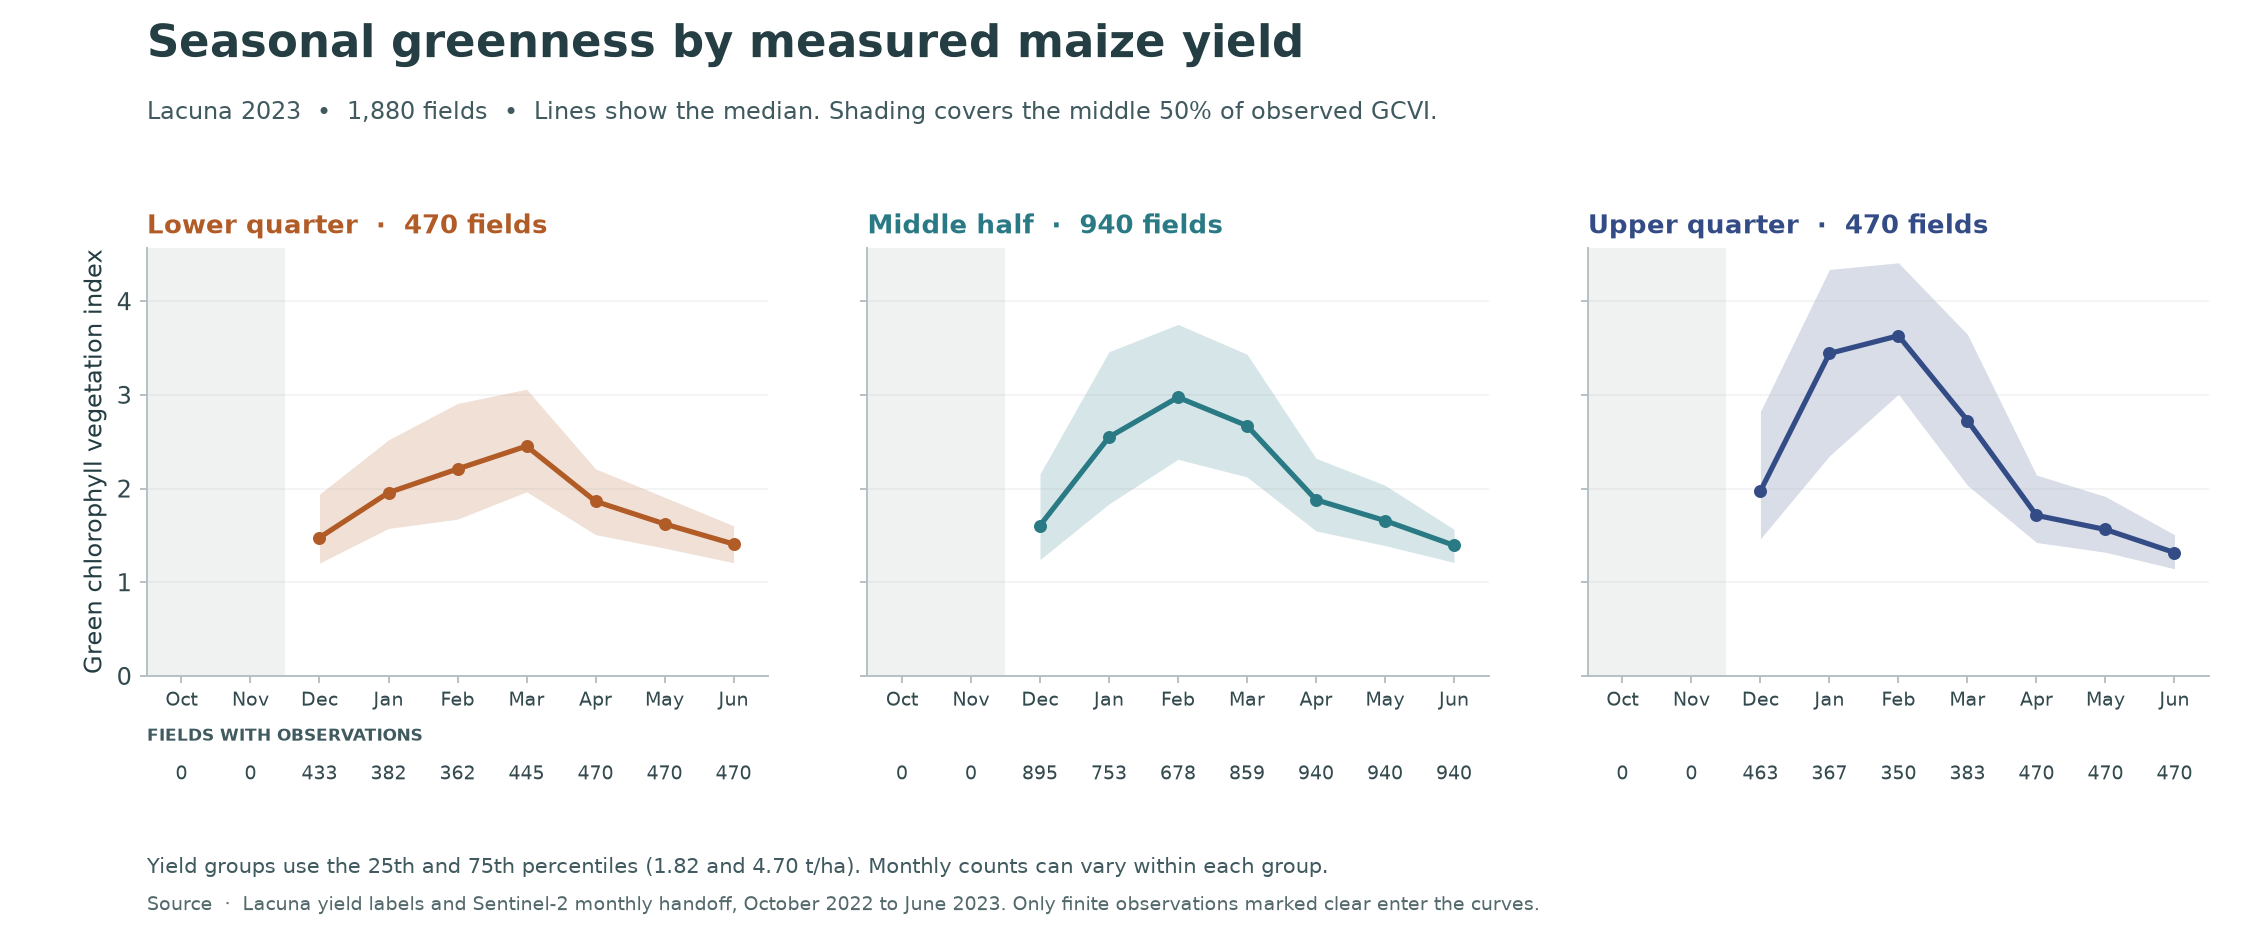

In [7]:
from scripts.paper.atlas_diagnostics import build_diagnostics

diagnostics = build_diagnostics(ROOT, OUT)
show_file(diagnostics["seasonal_gcvi"])

In February, median GCVI was 3.63 in the upper yield quarter and 2.21 in the lower quarter. The shading shows the middle half of the available observations within each group. The counts below the curves show how many fields contributed in each month. Groups were formed using the measured harvest yield, so the comparison describes the growing seasons of those fields. [Full-size seasonal curves](../results/visual_atlas/seasonal_gcvi.png).

### Agreement with crop cuts at two scales

Jin et al. Fig. 4 compares crop cuts and satellite estimates at district scale. The top row here shows individual Zimbabwe fields. The bottom row averages those same observations within each of the 19 provider administrative units, with equal weight per unit for the area scores. Each dot uses predictions from the **data v2 Presto experiment** on 1,504 development fields. A1 uses seasonal vegetation indices. P0 fits Ridge to frozen Presto embeddings generated by that experiment. These runs allowed fold 0 to supply training fields and scored folds 1–4. The reported R² uses the pooled sum of squared prediction errors at each scale. [Experiment protocol](../experiments/presto_finetune/PLAN.md) · [Saved scores](../experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/scores.csv).

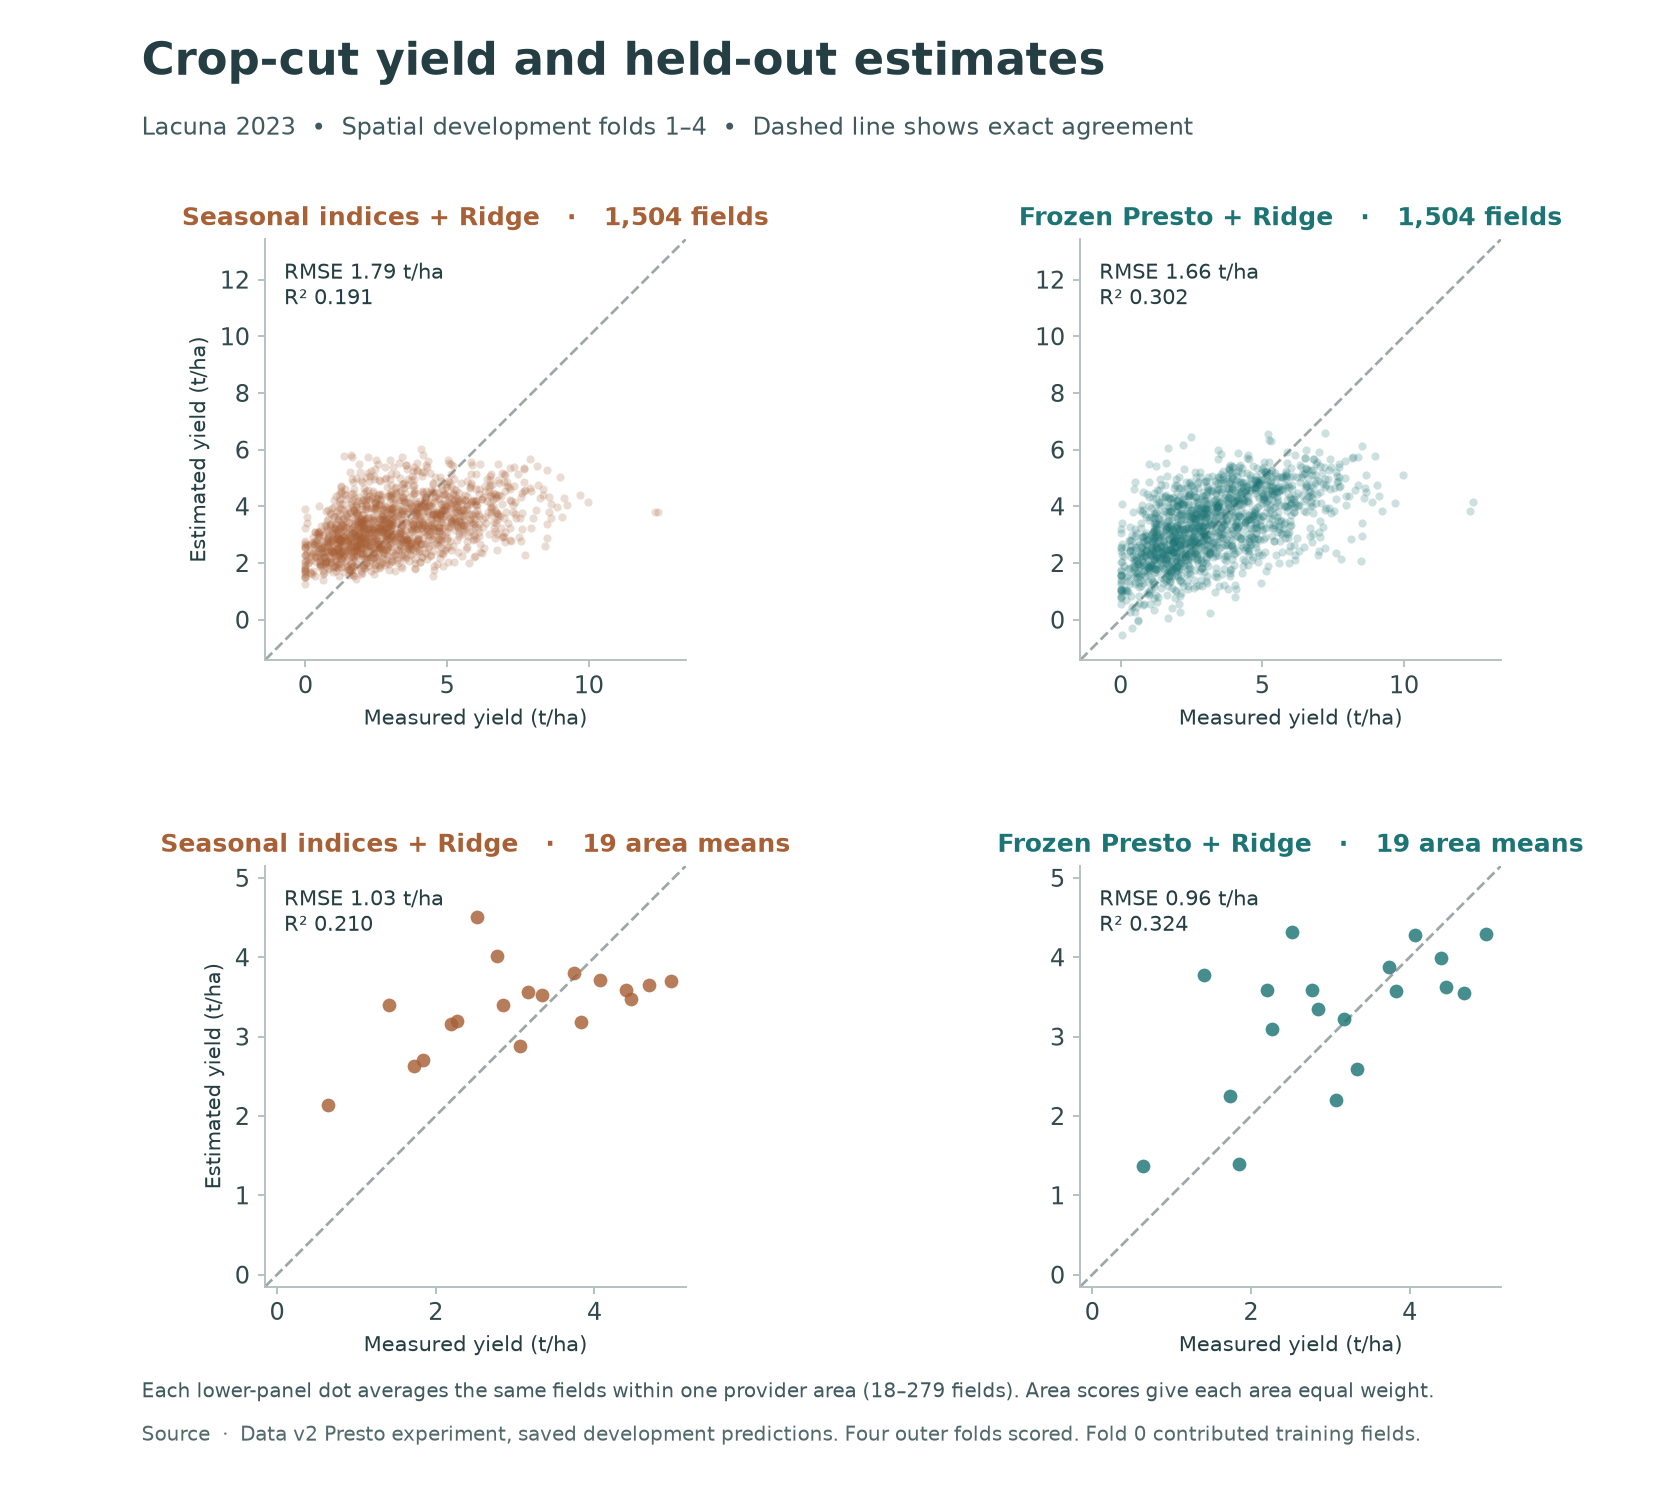

In [8]:
show_file(diagnostics["yield_agreement"])

The dashed diagonal marks exact agreement. A point below the line means the model estimated less maize than the crop cut measured. On the same 1,504 fields, seasonal-index Ridge had an RMSE of 1.79 t/ha and R² of 0.191. Frozen Presto with Ridge had an RMSE of 1.66 t/ha and R² of 0.302. The lower row changes the unit of comparison to the mean within each of 19 provider areas. [Full-size agreement plot](../results/visual_atlas/yield_agreement.png).

## How regional weather and measured yield vary together

Jin et al. Fig. 7a compared yield and soil variables. Here the environmental variables are the four seasonal rainfall and temperature features available in Zimbabwe. A square gives the Pearson correlation across sampled NASA POWER cells within a single harvest and provider. We average v2 primary crop-cut yields first, require at least five primary fields per cell, and give each retained cell equal weight. This keeps multiple fields that share a weather estimate from appearing as separate weather observations. The threshold is a display choice. Spatial dependence and differences in the sampled farms affect these descriptive associations. [NASA source and processing](../docs/zimbabwe/METHODS.md#weather-extraction-and-features).

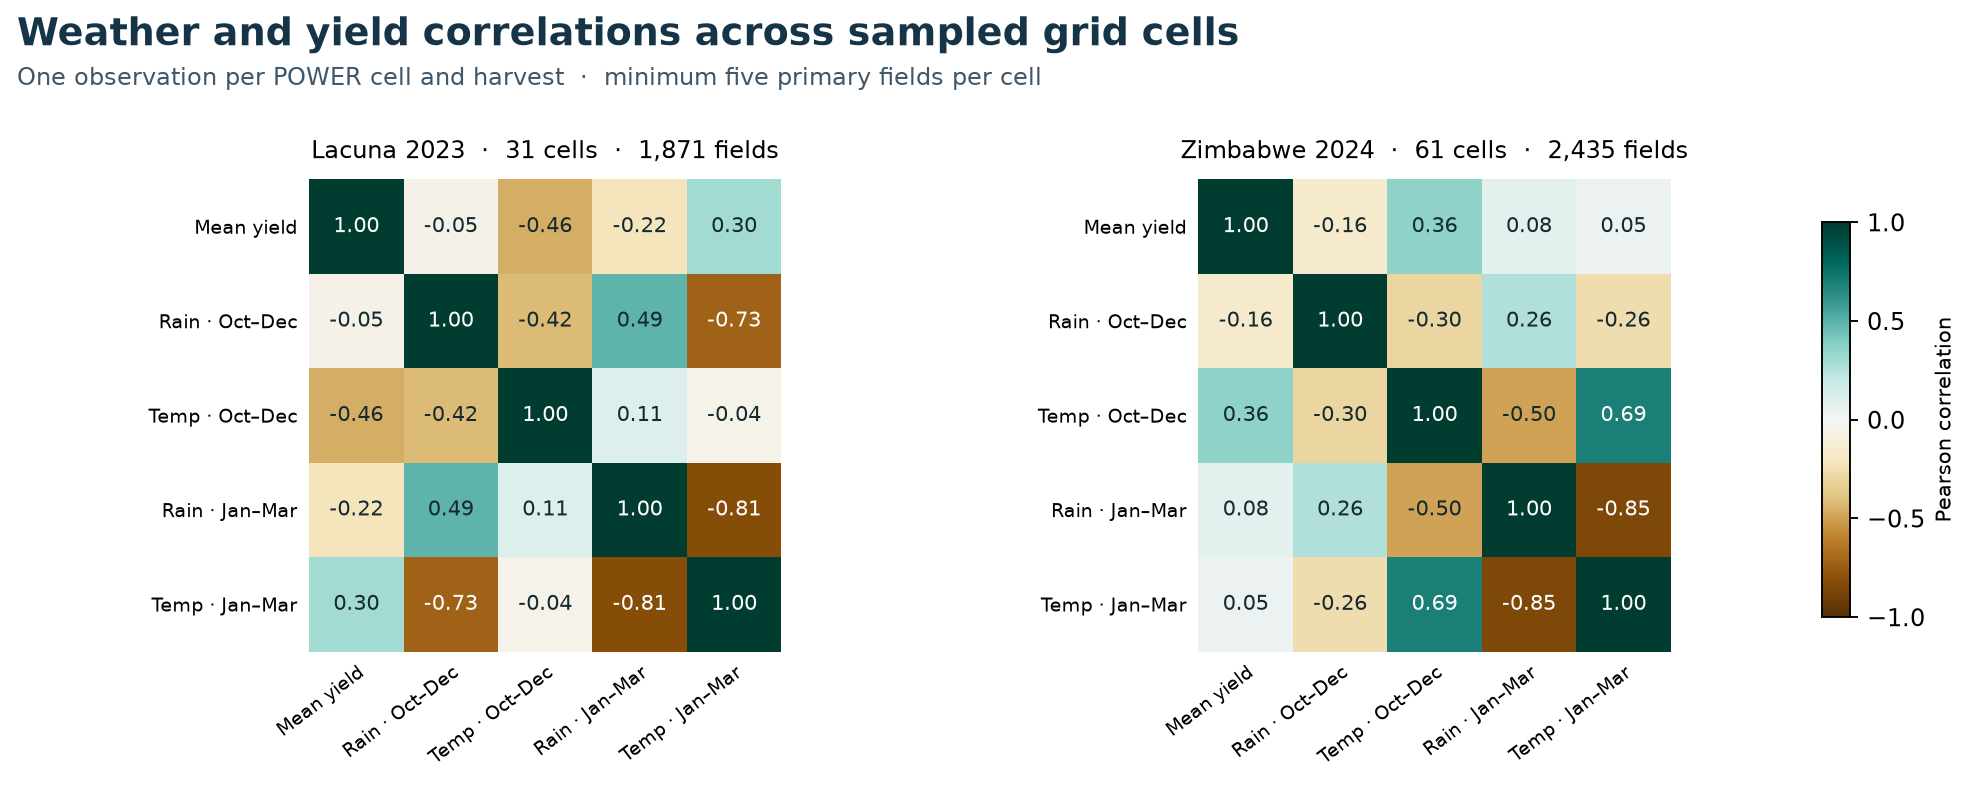

In [9]:
from cropyield.experiments.zimbabwe_weather_compact import early_weather

keys = ["weather_grid_id", "season_year"]
# Use the same October–December calculation as the project's compact-weather experiments.
early = early_weather(pd.read_parquet(weather_dir / "weather_cell_months.parquet"))
weather_cols = {
    "wx_rain_percent_normal_oct_dec": "Rain · Oct–Dec",
    "wx_t2m_anomaly_c_oct_dec": "Temp · Oct–Dec",
    "wx_rain_percent_normal_jan_mar": "Rain · Jan–Mar",
    "wx_t2m_anomaly_c_jan_mar": "Temp · Jan–Mar",
}
primary = fields.loc[fields.include_primary].merge(early, on=keys, validate="many_to_one")
by_cell = primary.groupby(keys)
assert by_cell[list(weather_cols)].nunique(dropna=False).eq(1).all().all()
sampled_cells = by_cell.size().rename("fields").to_frame().join(
    by_cell.yield_t_ha.mean().rename("Mean yield")).join(by_cell[list(weather_cols)].first())
sampled_cells = sampled_cells.loc[sampled_cells.fields.ge(5)].rename(columns=weather_cols).reset_index()
sampled_cells.to_csv(OUT / "weather_yield_cell_means.csv", index=False)

cols = ["Mean yield", *weather_cols.values()]
fig, axes = plt.subplots(1, 2, figsize=(11.8, 5.05))
fig.subplots_adjust(left=.13, right=.89, top=.79, bottom=.24, wspace=.40)
fig.suptitle("Weather and yield correlations across sampled grid cells", x=.025, y=.98,
             ha="left", fontsize=16, fontweight="bold", color="#163447")
fig.text(.025, .90, "One observation per POWER cell and harvest  ·  minimum five primary fields per cell",
         fontsize=10, color="#40576A")
for ax, (year, group) in zip(axes, sampled_cells.groupby("season_year", sort=True)):
    corr = group[cols].corr()
    im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
    ax.set(xticks=range(len(cols)), yticks=range(len(cols)), yticklabels=cols)
    ax.set_xticklabels(cols, rotation=37, ha="right", rotation_mode="anchor")
    ax.tick_params(labelsize=8, length=0, pad=5)
    ax.set_title(f"{season_names[year]}  ·  {len(group)} cells  ·  {group.fields.sum():,} fields",
                 fontsize=10, pad=9)
    for i in range(len(cols)):
        for j in range(len(cols)):
            v = corr.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if abs(v) >= .60 else "#142A2E", fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
bar = fig.colorbar(im, cax=fig.add_axes([.925, .28, .014, .46]), ticks=[-1, -.5, 0, .5, 1])
bar.set_label("Pearson correlation", fontsize=9)
export_figure(fig, "weather_yield_correlations.png")

Here *rain* is percent of the 1991–2020 normal and *temperature* is departure from the normal in °C. October–December belongs to the calendar year before the harvest. Each coefficient describes variation across the sampled cells within one season. Weather, field management and sampling locations can all vary together. [Cell-level data behind the figure](../results/visual_atlas/weather_yield_cell_means.csv). [Full-size correlation matrices](../results/visual_atlas/weather_yield_correlations.png).

## Repository figure gallery

The gallery inventories the tracked project at the start of this atlas, revision [8de629a](https://github.com/FelixYu120/DSC-291-Final-Project/tree/8de629a). It covers standalone images, images embedded in active and archived notebooks, project diagrams, and provider illustrations. Source files that contain identical images share a gallery ID. The gallery also reconstructs report and Presto figures where the plotting code and numeric data were saved separately.

Use the contact sheets to browse. The links below them give the original file and, for notebook figures, the cell and output number. The CSV indexes every source occurrence. For a full-size view in Jupyter set the figure ID in the last cell. Rebuilding this section uses local Git history including revision 8de629a. [Full source index](../results/visual_atlas/figure_inventory.csv).

Every gallery ID has a caption immediately beneath its contact sheet. The source inventory and full-size view also include these captions. The provider’s countrywide modeled-yield illustration is G079 in the provider documentation group.

In [10]:
from scripts.paper.visualization_gallery import GROUPS, collect_gallery, show_gallery, show_figure

gallery = collect_gallery(ROOT)
assert all(item.description.strip() for item in gallery.items.values()), "Every gallery figure needs a caption"
gallery.write_manifest(OUT / "figure_inventory.csv")
print(f"{len(gallery.items)} unique figures · {len(gallery.rows)} source occurrences")
display(pd.Series(gallery.counts(), name="Unique figure previews").to_frame())

106 unique figures · 118 source occurrences


,Unique figure previews
Standalone project figures,16
Archived notebook figures,26
Notebook figures,27
Archived project diagrams,3
Provider documentation figures,12
Reconstructed v2 report figures,4
Reconstructed Presto diagnostics,18


### Standalone project figures

16 unique previews · 16 figures referenced in this section.

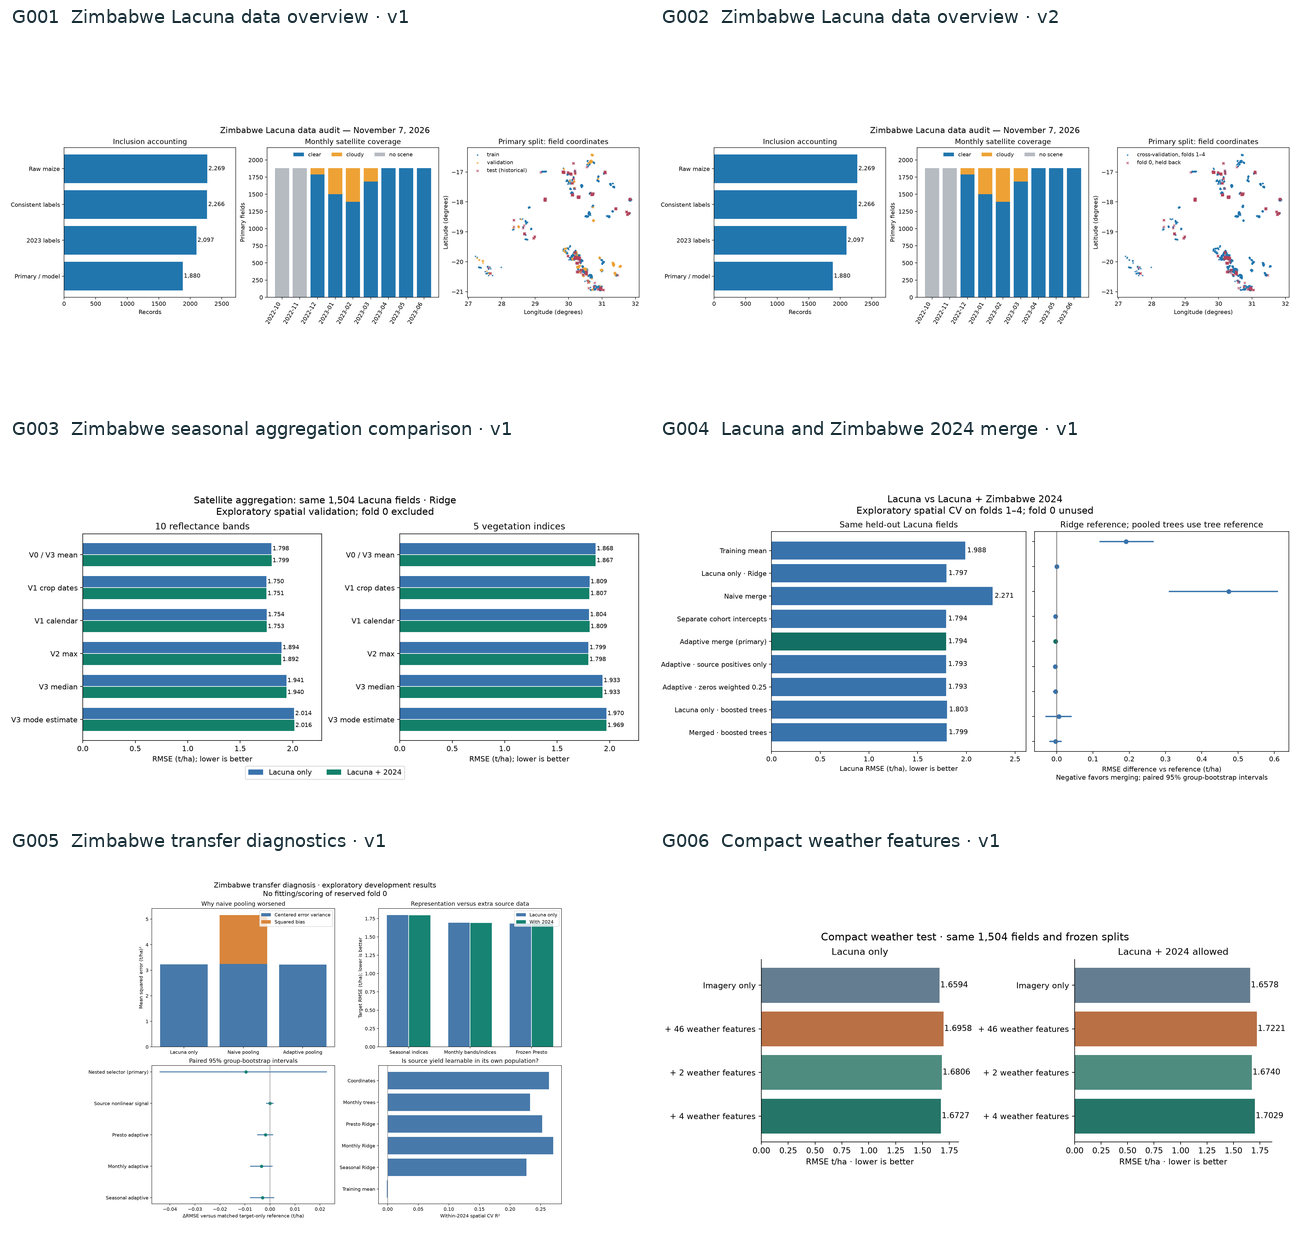

- **G001** The right panel locates the 1,880 primary Lacuna 2023 fields. Blue, orange and red mark the v1 training, validation and historical test labels. The other panels account for exclusions and monthly satellite coverage. [data_overview.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/processed/zimbabwe_midterm_v1/data_overview.png)

- **G002** The right panel locates the same 1,880 primary Lacuna 2023 fields under the v2 split labels. Blue denotes development folds 1–4 and red denotes the held-back fold 0. The left panels show which records and months are available. [data_overview.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/processed/zimbabwe_midterm_v2/data_overview.png)

- **G003** The v1 Ridge models summarize ten reflectance bands or five vegetation indices over alternative season windows. Paired bars give RMSE on the same 1,504 Lacuna fields for training with Lacuna alone and with 2024 records added. Shorter bars indicate smaller errors. [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_aggregation_v1/comparison.png)

- **G004** Each bar gives held-out Lacuna RMSE for one v1 training strategy. Dots at right show its difference from a matched Lacuna-only reference, with paired 95% spatial-group bootstrap intervals. Values left of zero favor the model being compared. [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_merge_v1/comparison.png)

- **G005** The v1 panels decompose squared error into bias and variance, compare seasonal, monthly and Presto features, and show uncertainty in the effect of adding 2024 records. The lower-right panel tests how well the 2024 source can predict its own held-out yields. [diagnosis.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_transfer_diagnosis_v1/diagnosis.png)

- **G006** Bars give v1 tree-model RMSE on 1,504 Lacuna fields using imagery alone or with 46, two or four weather features. Compare the bars within each training panel to see how weather changes error, and corresponding bars across panels to see how adding 2024 records changes it. [compact_weather_comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_weather_compact_v1/compact_weather_comparison.png) · [data_guide_2_zimbabwe.ipynb · cell 41, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

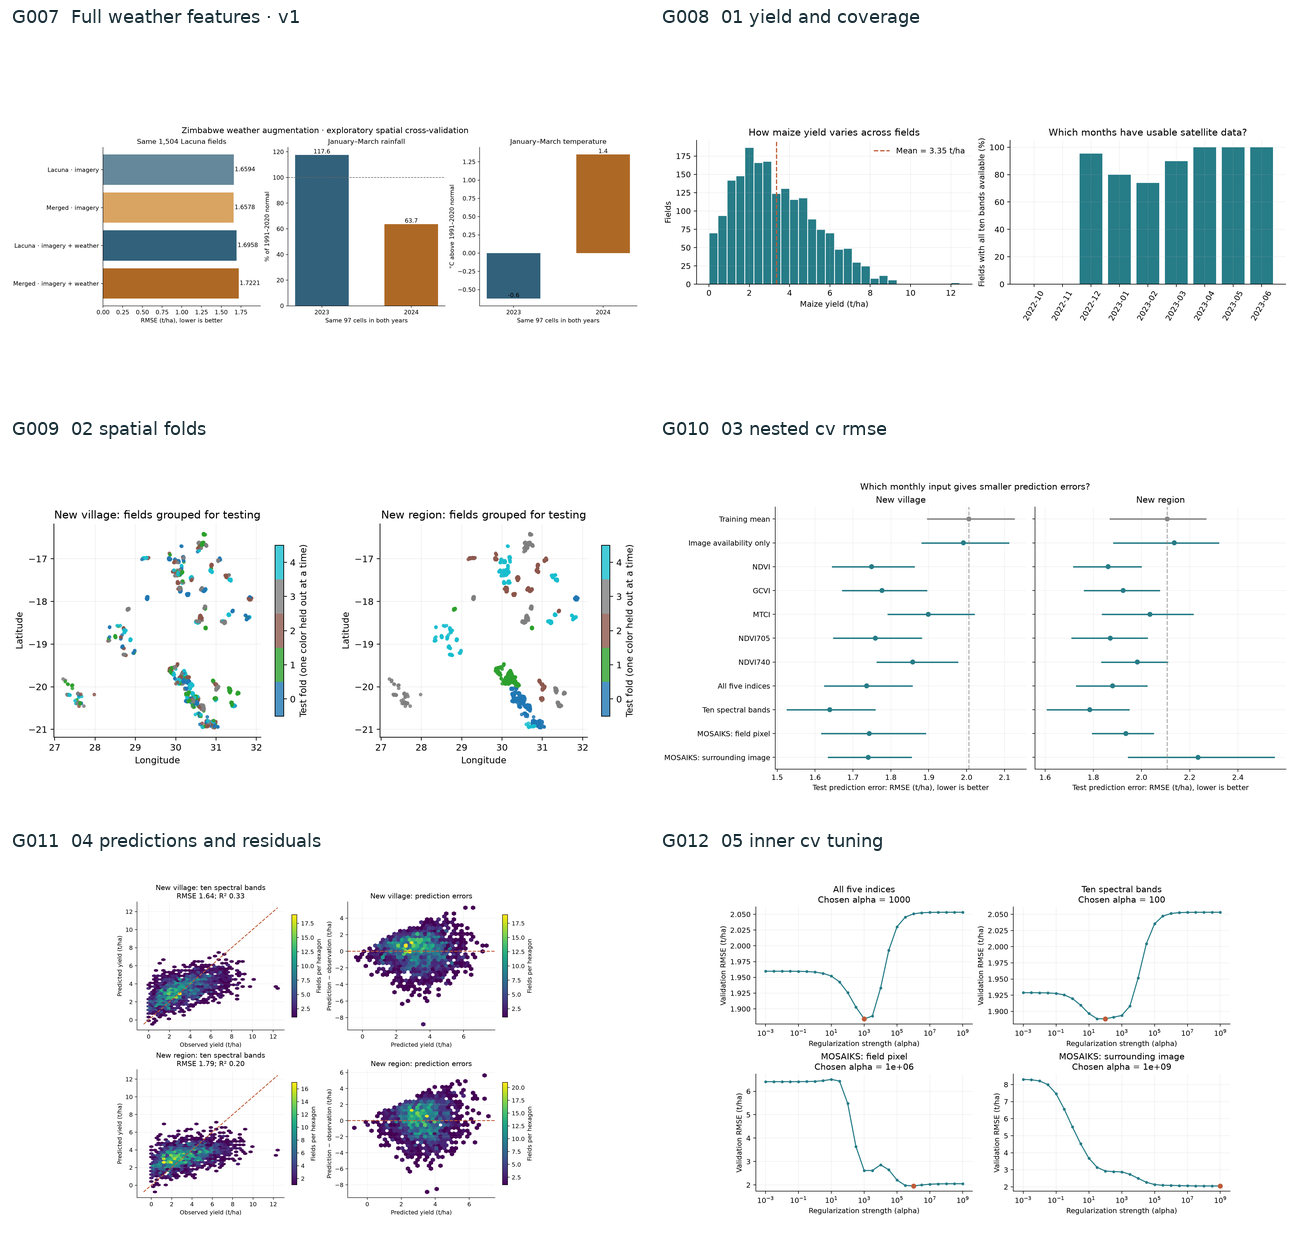

- **G007** The left panel compares v1 held-out errors for imagery and weather models trained with and without 2024 records. The other panels average January–March rainfall percent of normal and temperature departures over the same 97 weather cells in each year. [weather_comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/runs/zimbabwe_weather_v1/weather_comparison.png)

- **G008** The histogram counts Lacuna fields by measured maize yield in tonnes per hectare. Its dashed line shows the mean. The adjacent bars show the percentage of fields with all ten satellite bands available in each month. [01_yield_and_coverage.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/01_yield_and_coverage.png)

- **G009** Each dot locates a Lacuna 2023 field. Colors identify the five test folds. The left panel assigns nearby villages to folds, while the right panel holds together fields in the same provider region. [02_spatial_folds.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/02_spatial_folds.png)

- **G010** Each dot gives a monthly-input model’s held-out RMSE in t/ha, with a 95% spatial-group bootstrap interval. The panels hold out villages or regions, and the dashed line marks the training-mean baseline. Farther left means smaller error. [03_nested_cv_rmse.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/03_nested_cv_rmse.png)

- **G011** The left panels compare measured and predicted yield for the monthly-band models. Color counts fields in each hexagon. The right panels show prediction minus observation against predicted yield, with positive errors above the horizontal reference. [04_predictions_and_residuals.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/04_predictions_and_residuals.png)

- **G012** For four monthly feature sets, each curve plots inner-validation RMSE against Ridge regularization strength on a logarithmic axis. The orange dot marks the minimum selected for regional outer fold 0. [05_inner_cv_tuning.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/05_inner_cv_tuning.png)

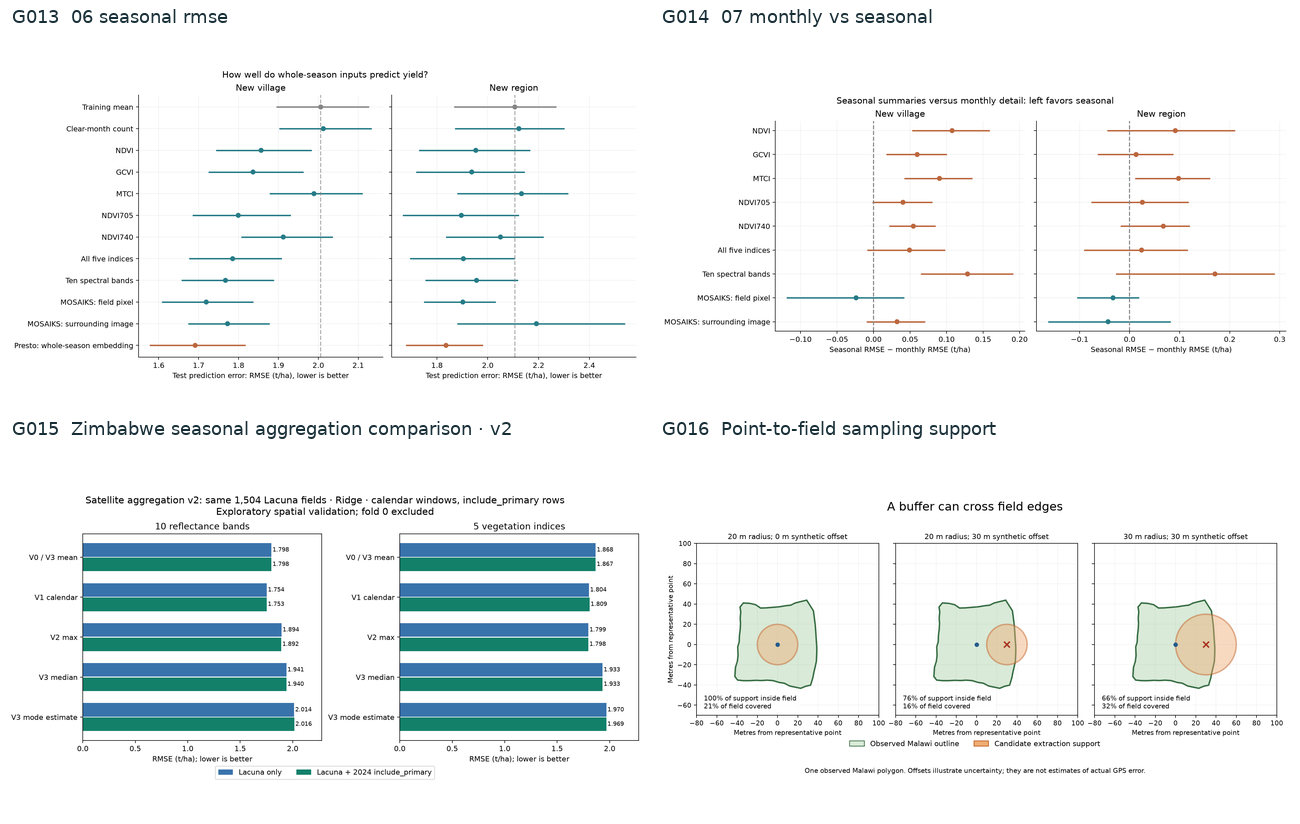

- **G013** Dots compare the held-out RMSE of whole-season features for new villages and new regions. Horizontal lines give 95% spatial-group bootstrap intervals. The dashed reference gives the RMSE of predicting the training mean. [06_seasonal_rmse.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/06_seasonal_rmse.png)

- **G014** Each dot subtracts monthly-input RMSE from seasonal-summary RMSE for the same feature family and held-out fields. A value left of zero favors seasonal aggregation. The lines give paired 95% spatial-group bootstrap intervals. [07_monthly_vs_seasonal.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baseline_results/07_monthly_vs_seasonal.png)

- **G015** For the v2 experiment, paired bars compare Lacuna-only and combined-source Ridge fits on the same 1,504 Lacuna fields. The two panels show ten bands and five vegetation indices. The December–March calendar mean uses the same window for both providers. [comparison.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/aggregation_v2/comparison.png)

- **G016** The green boundary is a surveyed Malawi field. Each orange circle is a proposed sampling area. Increasing its radius or shifting its center 30 m moves part of the circle across the surveyed boundary. [point_area_example.png · Image file](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/quality_remediation/point_area_example.png) · [data_quality_review.ipynb · cell 30, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

In [11]:
show_gallery(gallery, "Standalone project figures")

### Notebook figures

27 unique previews · 29 figures referenced in this section.

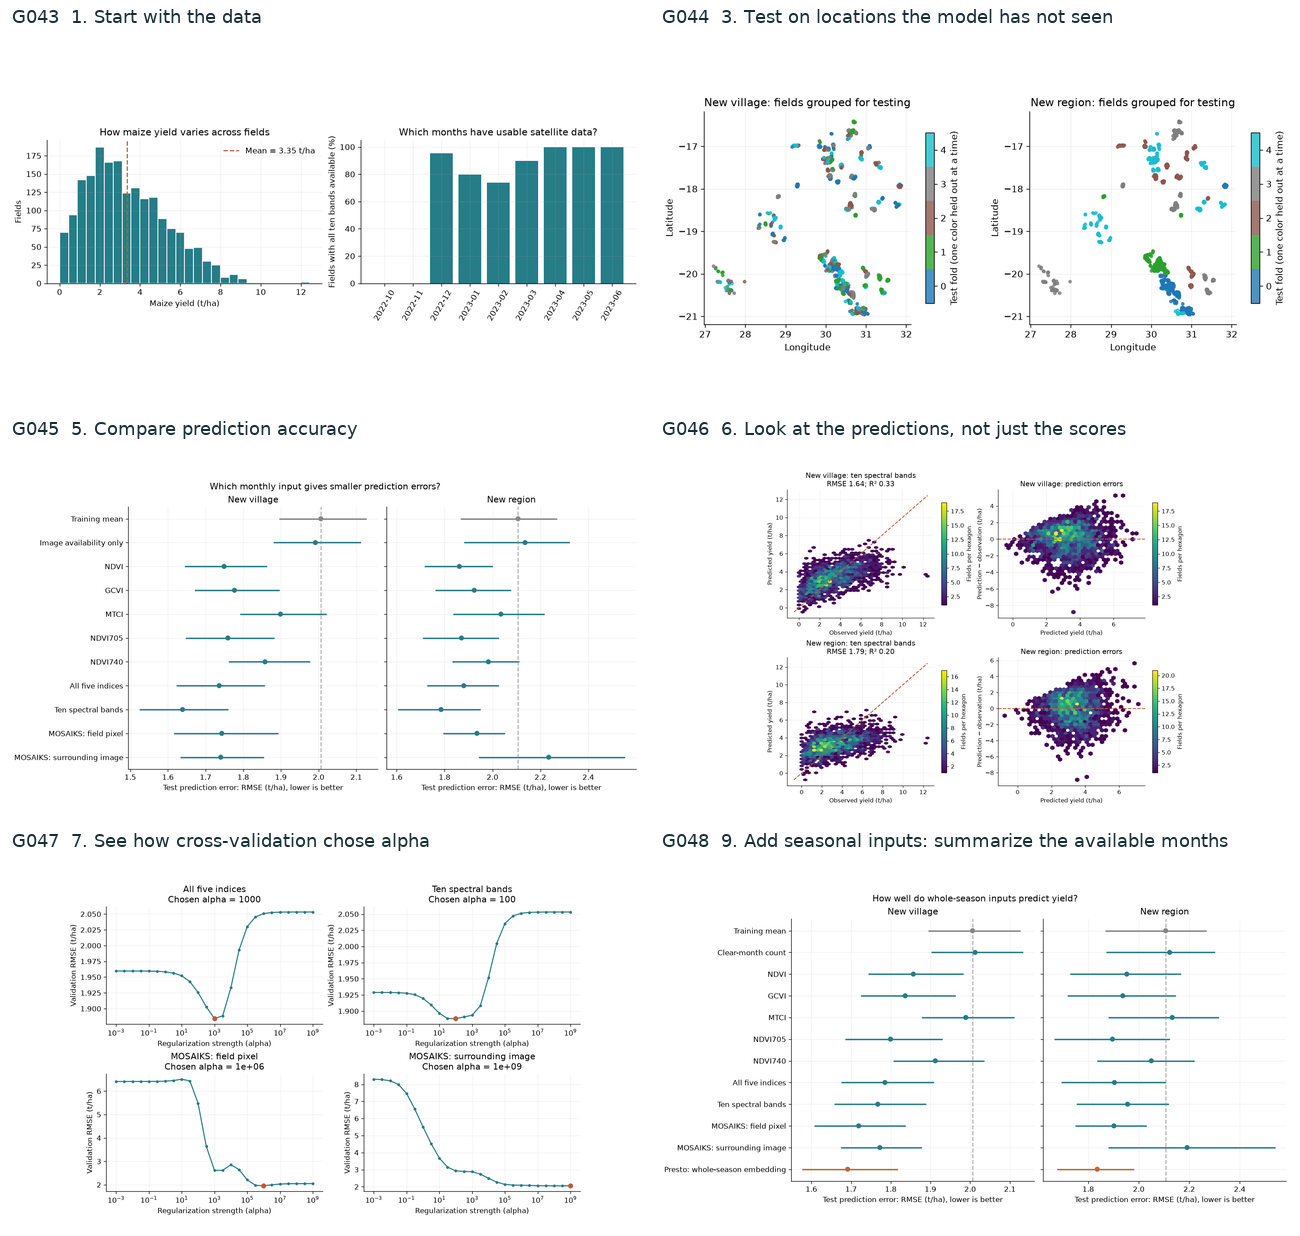

- **G043** The histogram counts Lacuna fields by measured maize yield in tonnes per hectare. Its dashed line shows the mean. The adjacent bars show the percentage of fields with all ten satellite bands available in each month. [baselines.ipynb · cell 6, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G044** Each dot locates a Lacuna 2023 field. Colors identify the five test folds. The left panel assigns nearby villages to folds, while the right panel holds together fields in the same provider region. [baselines.ipynb · cell 12, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G045** Each dot gives a monthly-input model’s held-out RMSE in t/ha, with a 95% spatial-group bootstrap interval. The panels hold out villages or regions, and the dashed line marks the training-mean baseline. Farther left means smaller error. [baselines.ipynb · cell 21, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G046** The left panels compare measured and predicted yield for the monthly-band models. Color counts fields in each hexagon. The right panels show prediction minus observation against predicted yield, with positive errors above the horizontal reference. [baselines.ipynb · cell 24, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G047** For four monthly feature sets, each curve plots inner-validation RMSE against Ridge regularization strength on a logarithmic axis. The orange dot marks the minimum selected for regional outer fold 0. [baselines.ipynb · cell 27, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G048** Dots compare the held-out RMSE of whole-season features for new villages and new regions. Horizontal lines give 95% spatial-group bootstrap intervals. The dashed reference gives the RMSE of predicting the training mean. [baselines.ipynb · cell 36, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

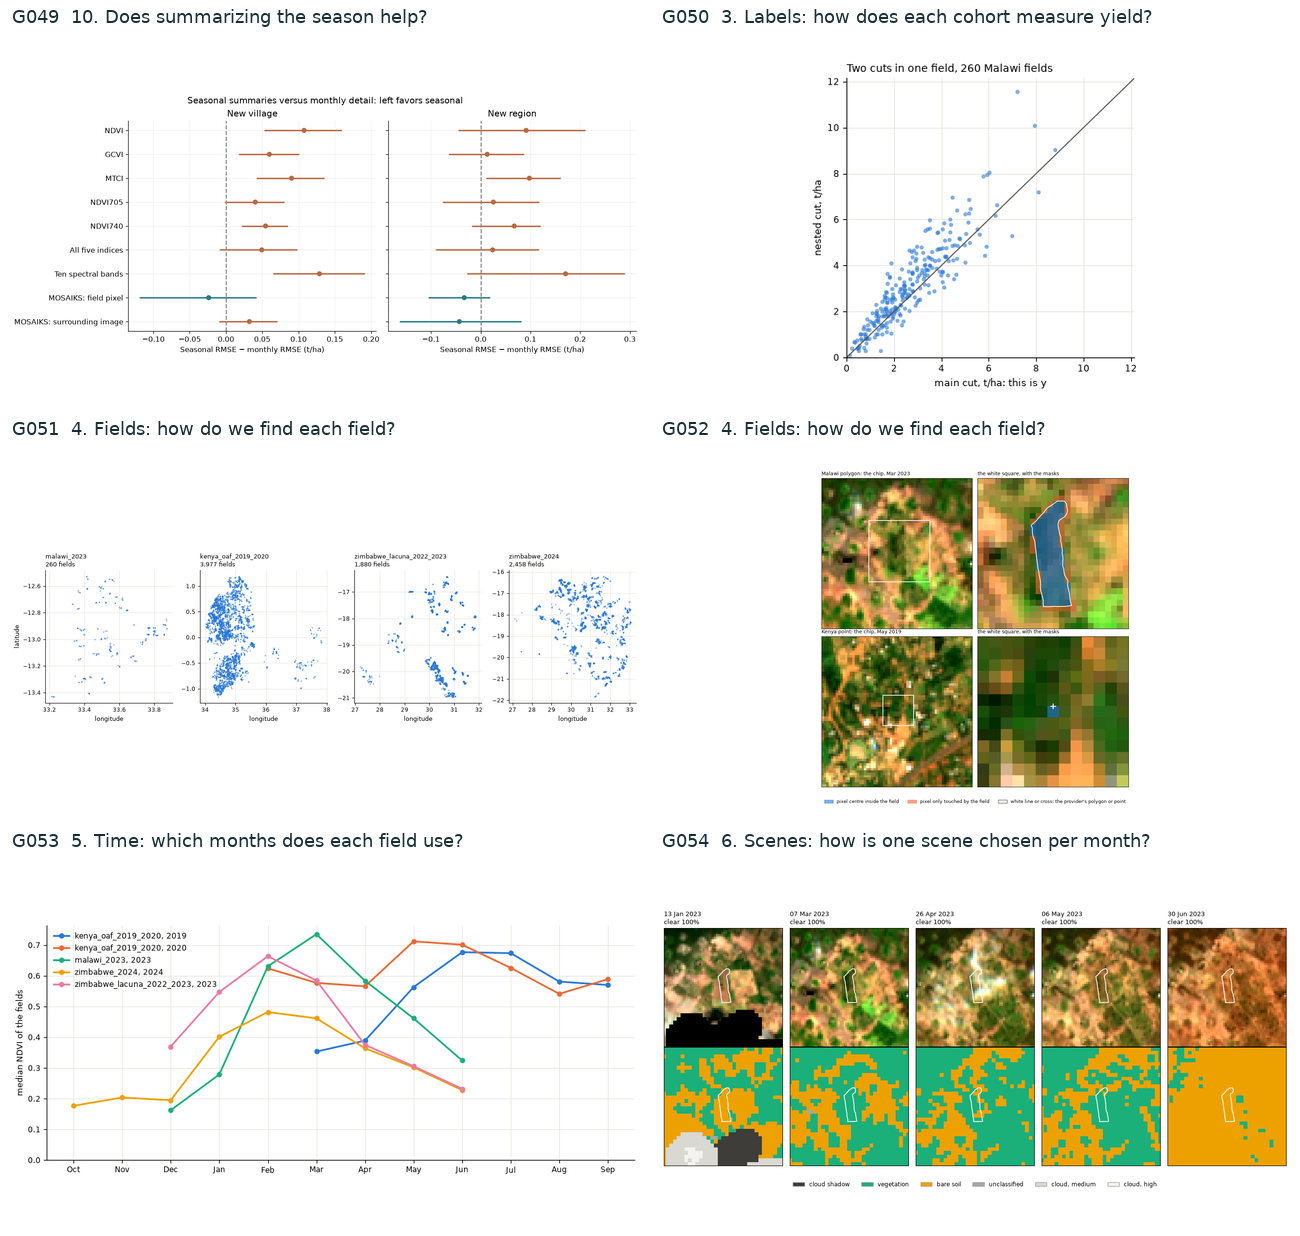

- **G049** Each dot subtracts monthly-input RMSE from seasonal-summary RMSE for the same feature family and held-out fields. A value left of zero favors seasonal aggregation. The lines give paired 95% spatial-group bootstrap intervals. [baselines.ipynb · cell 38, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebook/baselines.ipynb)

- **G050** Each point compares two area-normalized measurements from the same Malawi field. Horizontal position gives main-cut yield and vertical position gives nested-cut yield in t/ha. Points above the diagonal have a larger nested-cut estimate. [data_guide.ipynb · cell 35, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G051** Blue dots locate the primary records in Malawi 2023, Kenya OAF, Lacuna and Zimbabwe 2024 using longitude and latitude. Each panel title gives its cohort and record count. [data_guide.ipynb · cell 37, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G052** The left column places a white zoom window on a Malawi polygon and a Kenya point. In the enlargements, blue marks pixels with centers inside the field, orange marks edge-only pixels, and the white outline or cross is the provider geometry. [data_guide.ipynb · cell 41, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G053** The lines show monthly median field NDVI among available primary observations for each cohort and harvest year. Months run from October through the following September so growing seasons can be read across calendar years. [data_guide.ipynb · cell 46, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G054** Five columns follow a Malawi field from January to June 2023. Visible-color images appear above their scene-classification masks. The white boundary marks the field, and the legend identifies cloud shadow, vegetation, bare soil and other classes. [data_guide.ipynb · cell 52, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

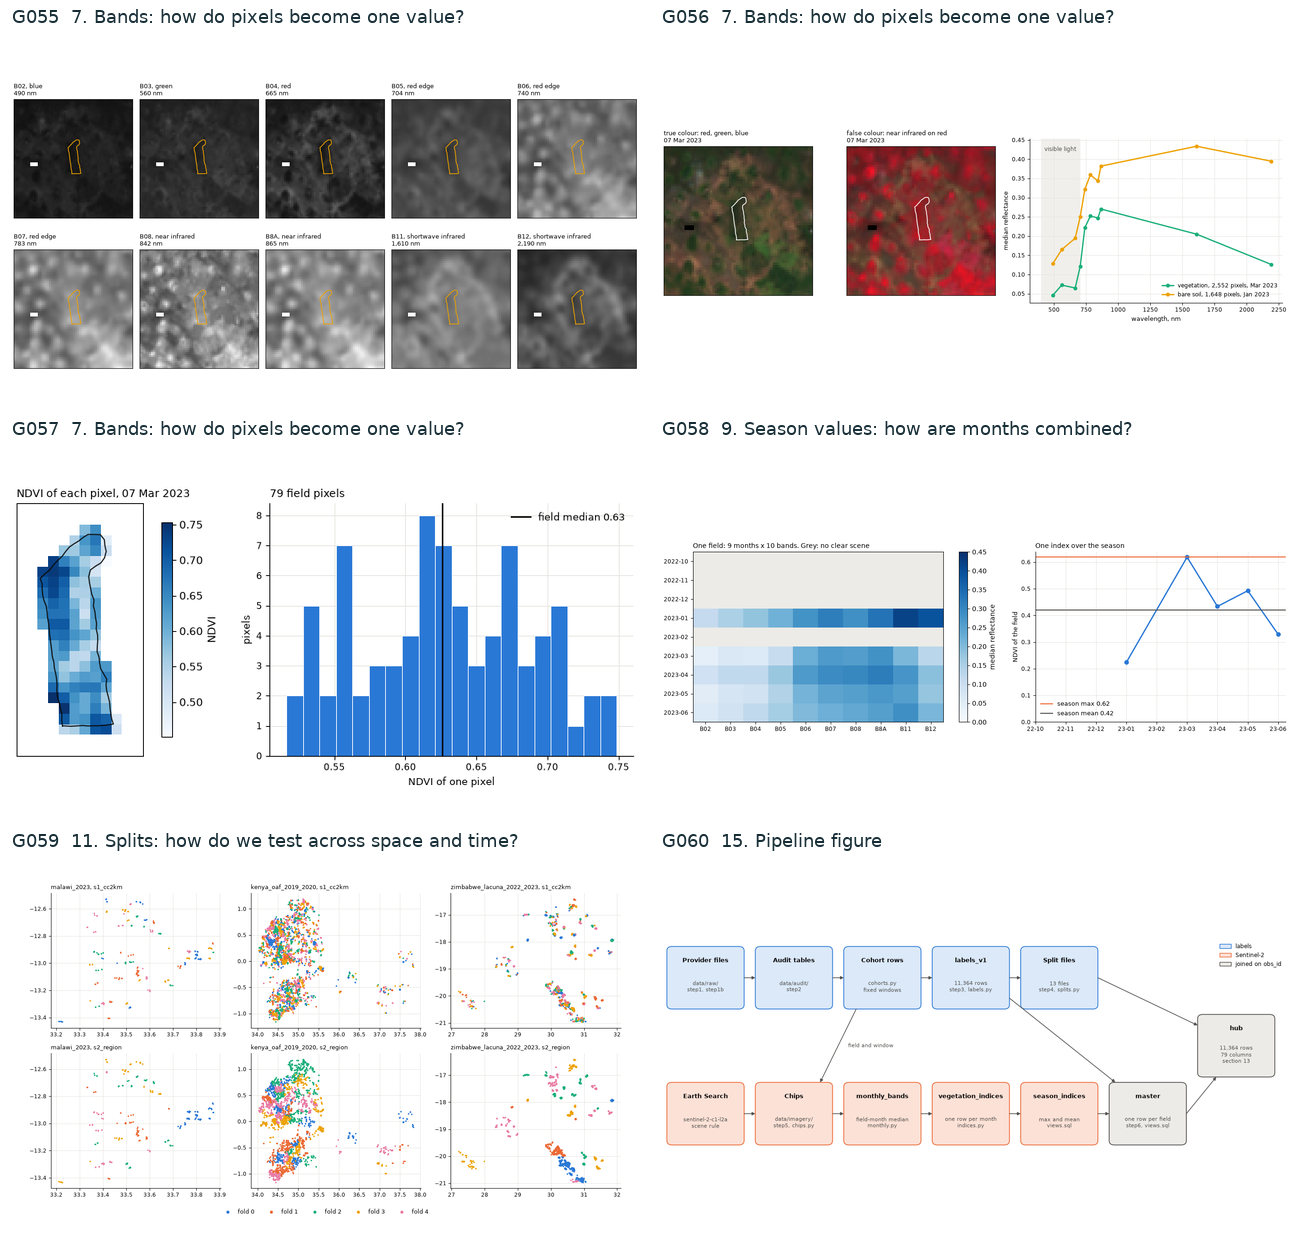

- **G055** Grayscale panels show ten spectral bands around the same Malawi field, outlined in orange. Lighter shades represent higher reflectance on a common scale. Wavelength labels distinguish the visible, red-edge and infrared bands. [data_guide.ipynb · cell 56, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G056** The first two panels show the same Malawi scene in visible color and near-infrared false color. Vegetation appears red in the second view. The wavelength plot at right compares vegetation, bare soil and the field median. [data_guide.ipynb · cell 58, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G057** Blue shades show NDVI across the outlined Malawi field on 7 March 2023. The adjacent histogram summarizes 79 interior pixels. The black line marks their median NDVI of 0.63. [data_guide.ipynb · cell 61, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G058** This field’s reflectance heatmap places months in rows and spectral bands in columns. Gray denotes months without clear imagery. The curve at right summarizes NDVI across the available months. [data_guide.ipynb · cell 70, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G059** For Malawi, Kenya and Lacuna, each point is a field and each color a test fold. The upper row groups locations using 2 km spatial connections. The lower row shows the regional split defined for each cohort. [data_guide.ipynb · cell 80, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G060** The diagram follows provider records and Sentinel-2 observations through label checks, monthly measurements, season summaries and the features used in modeling. Connecting lines identify the joins between the tables. [data_guide.ipynb · cell 94, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

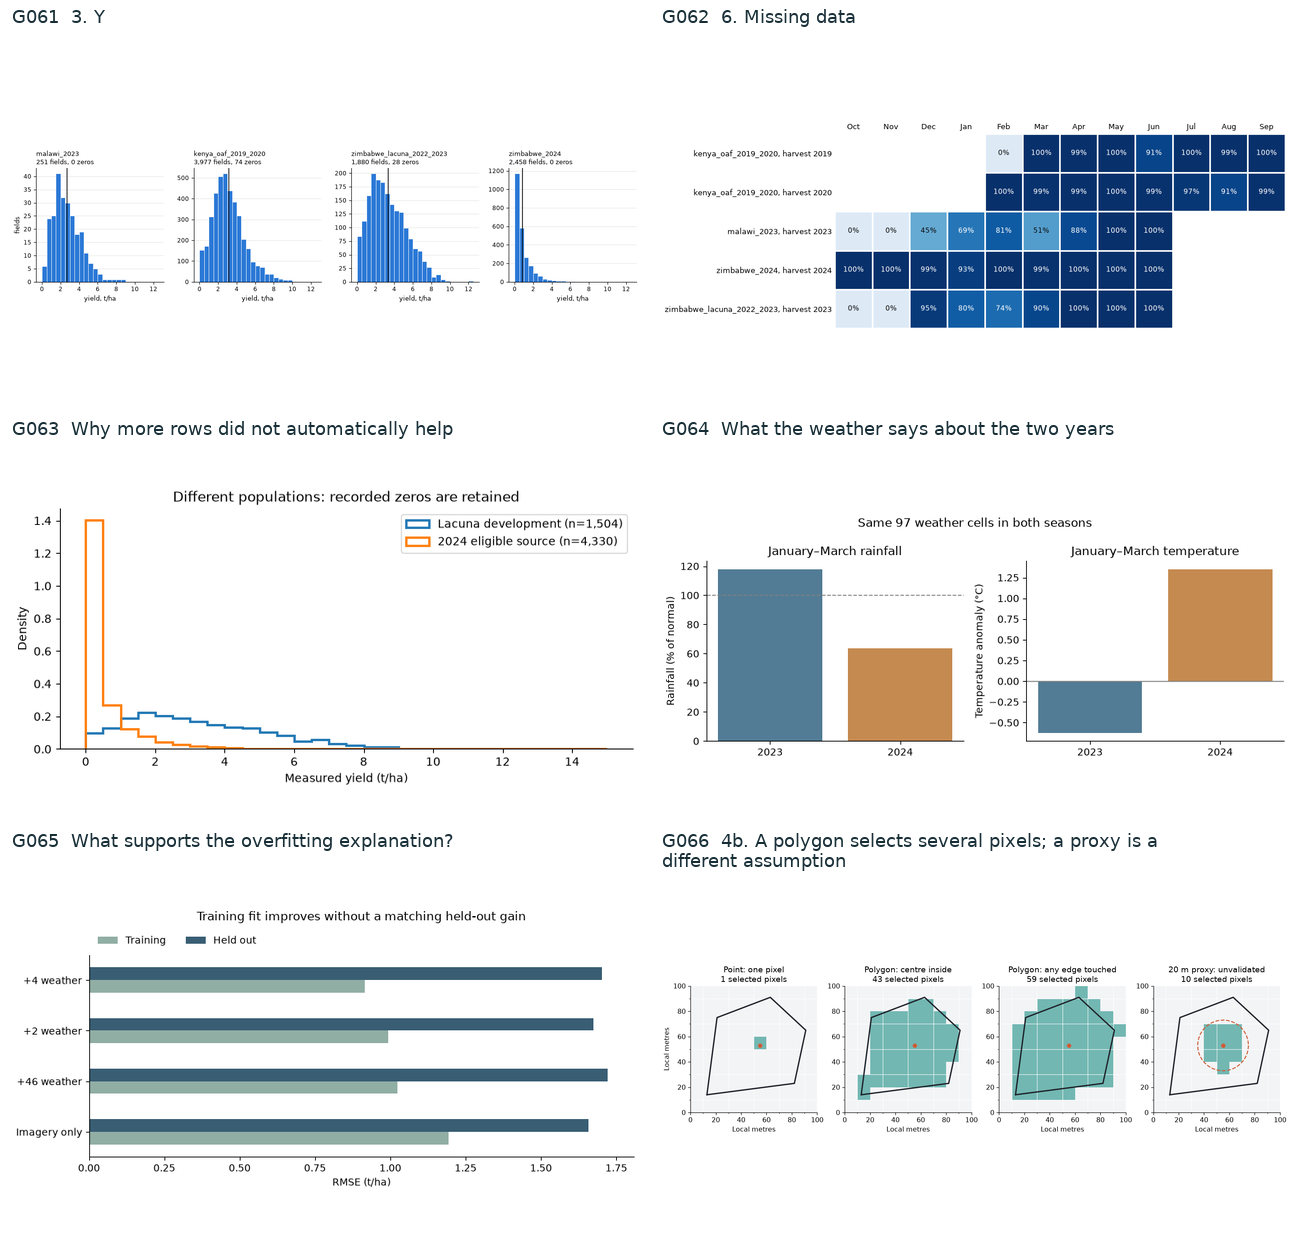

- **G061** Each panel counts fields in half-tonne-per-hectare yield bins for one modeling cohort. The vertical line marks that cohort’s mean. Panel titles give the field count and the number of zero yields. [data_guide.ipynb · cell 102, output 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G062** Each row combines a cohort and harvest year. Percentages and blue shading give the share with nonmissing satellite measurements for each calendar month. Blank cells fall outside the displayed season for that cohort. [data_guide.ipynb · cell 109, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide.ipynb)

- **G063** The density curves compare measured yields for 1,504 Lacuna development fields and 4,330 imagery-eligible Zimbabwe 2024 records in v1. Normalizing each curve by its sample size makes their shapes comparable. The 2024 curve includes recorded zero yields. [data_guide_2_zimbabwe.ipynb · cell 20, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

- **G064** The bars summarize January–March conditions across the same 97 NASA POWER cells in the 2023 and 2024 harvest seasons. The rainfall reference line marks 100% of normal and the temperature reference line marks a zero-degree departure. [data_guide_2_zimbabwe.ipynb · cell 38, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

- **G065** Paired bars compare training and held-out RMSE for merged v1 tree models with imagery alone or with 46, two or four weather features. The separation between bars shows how much prediction error grows on held-out fields. [data_guide_2_zimbabwe.ipynb · cell 43, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_guide_2_zimbabwe.ipynb)

- **G066** A synthetic field outline and point illustrate four pixel-selection rules. Teal cells show the pixels retained by a point, two polygon rules, and a 20 m circular proxy. Each panel reports the resulting count. [data_quality_review.ipynb · cell 17, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

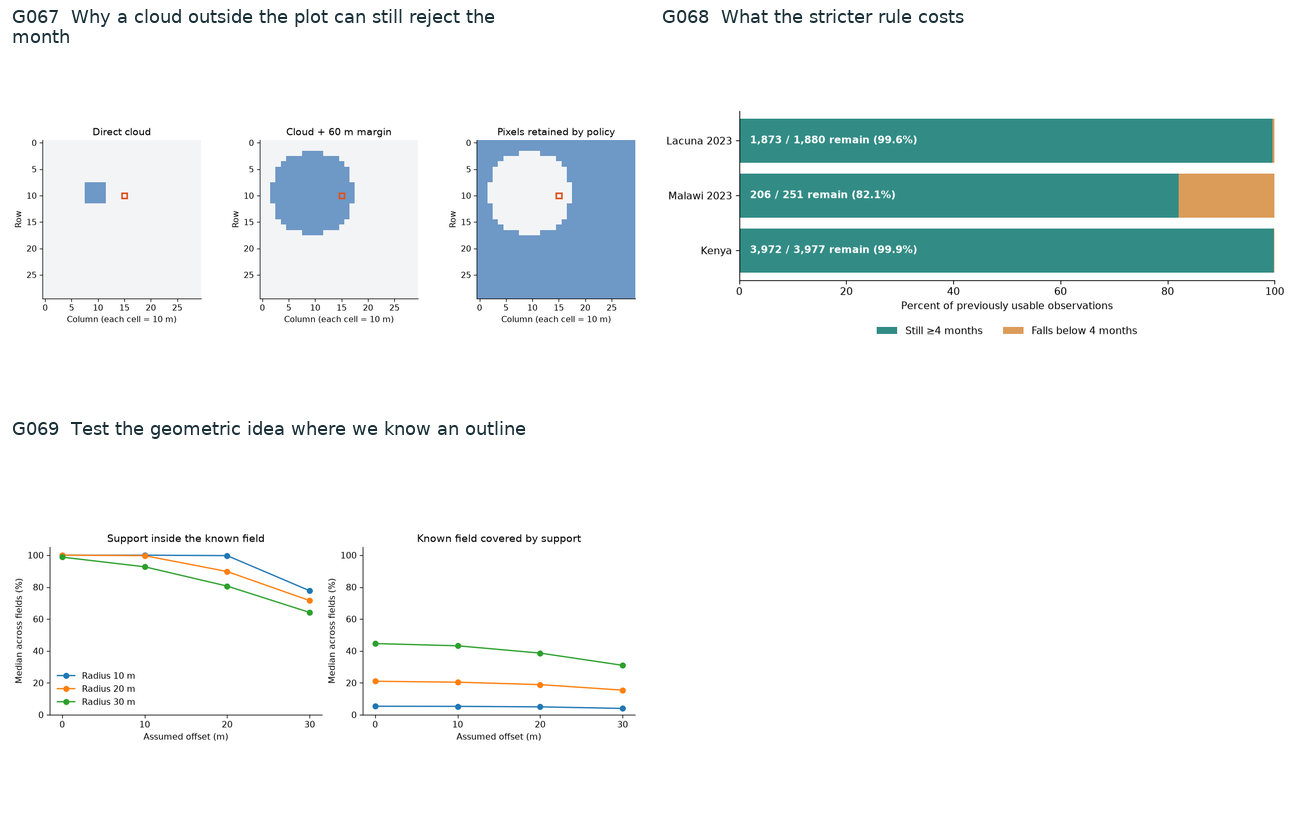

- **G067** On this synthetic 10 m grid, the left panel marks cloud pixels, the middle adds a 60 m margin, and the right shows retained pixels. The orange square locates an observation rejected because the margin reaches it. [data_quality_review.ipynb · cell 23, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

- **G068** Each stacked bar starts with the observations that met the original four-month rule. Teal shows the percentage still meeting it after stricter quality screening, while orange shows the percentage that lost sufficient coverage. [data_quality_review.ipynb · cell 25, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

- **G069** Rows of known Malawi field boundaries were tested with different circular sampling radii and simulated location offsets. The left curves show the median percentage of the circle inside the field. The right curves show the median percentage of the field covered by that circle. [data_quality_review.ipynb · cell 28, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/notebooks/data_quality_review.ipynb)

In [12]:
show_gallery(gallery, "Notebook figures")

### Archived notebook figures

26 unique previews · 26 figures referenced in this section.

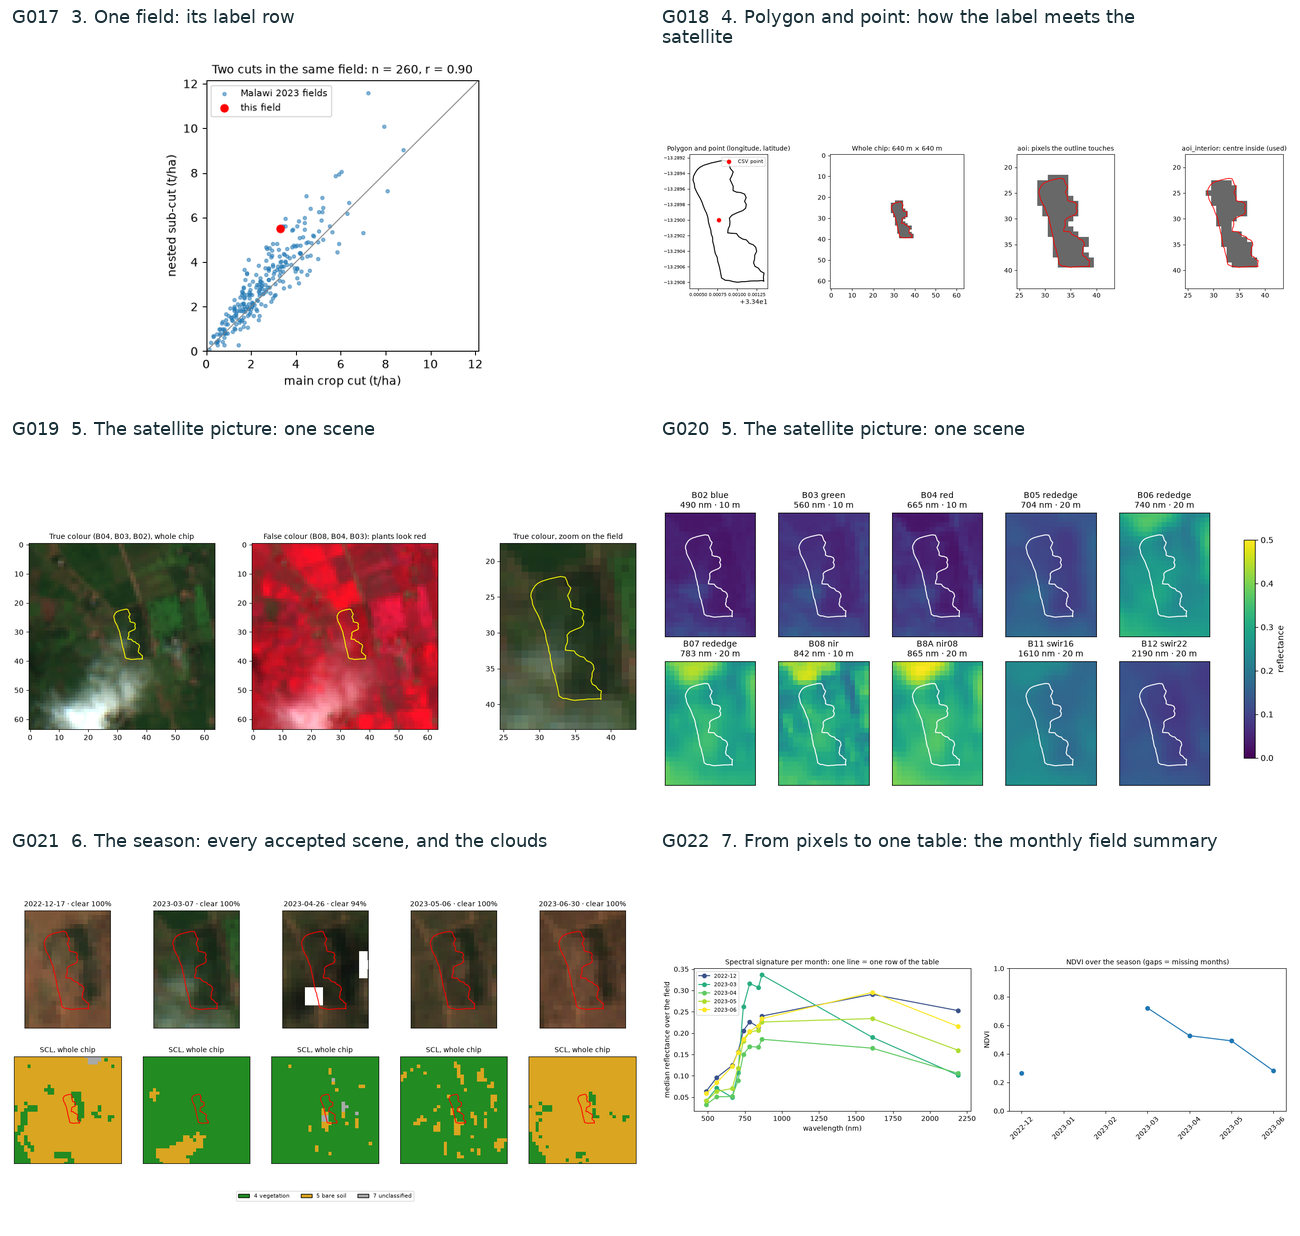

- **G017** Each Malawi 2023 field supplies a main crop cut on the horizontal axis and its nested subcut on the vertical axis, both in t/ha. The red point marks the example field. Distance from the diagonal shows how far its two measurements differ. [00_data_tour.ipynb · cell 8, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G018** The red point and black outline locate the same Malawi field. The following panels translate its outline to 10 m satellite pixels in a 640 m square. The last two compare all touched pixels with those whose centers lie inside. [00_data_tour.ipynb · cell 10, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G019** One Sentinel-2 acquisition shows a Malawi field outlined in yellow. The left and right views use visible light at two scales. The center assigns near-infrared reflectance to red, highlighting vegetation. [00_data_tour.ipynb · cell 13, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G020** All ten panels show the same outlined Malawi field on one date. Panel titles identify the Sentinel-2 band, wavelength and native resolution. The common color scale measures reflectance across the bands. [00_data_tour.ipynb · cell 13, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G021** Columns show five accepted scenes for the same Malawi field, outlined in red. The top row displays visible-color images. The lower row uses the legend to distinguish vegetation, bare soil and other scene classes across the surrounding chip. [00_data_tour.ipynb · cell 16, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G022** For the example Malawi field, each colored line gives median reflectance across wavelengths during one observed month. At right, NDVI follows that field through the growing season, with gaps where a monthly value is missing. [00_data_tour.ipynb · cell 21, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

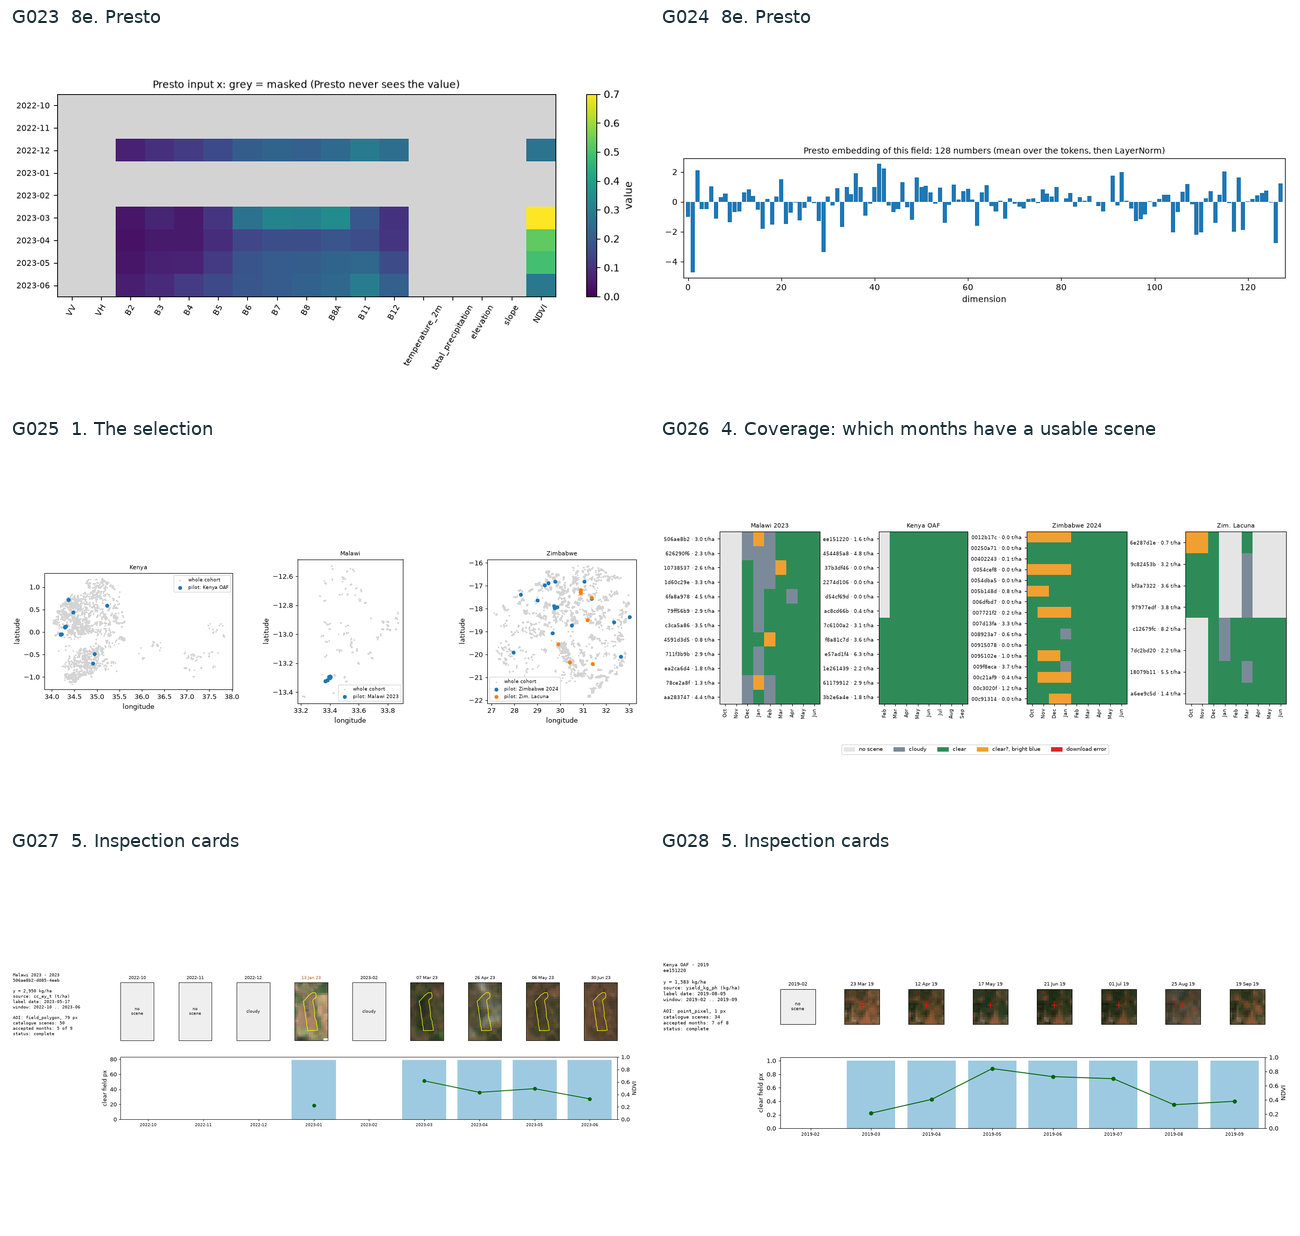

- **G023** Rows are months and columns are model inputs for the example Malawi field. Color shows the input value and gray marks entries masked before encoding. [00_data_tour.ipynb · cell 31, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G024** Each bar shows one component of the frozen Presto embedding for the example field. Bar height is the encoded feature value after token averaging and normalization. The full vector represents the field in subsequent models. [00_data_tour.ipynb · cell 34, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/00_data_tour.ipynb)

- **G025** Dots place fields by longitude and latitude in Kenya, Malawi and Zimbabwe. Gray dots give the full cohorts. Larger colored dots mark fields chosen for the archived 48-field imagery pilot. [02_pilot48.ipynb · cell 5, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G026** Each row is a pilot field and each column is a month. Colors distinguish clear observations, cloudy attempts, absent scenes, bright-blue flags and download errors across four cohorts. [02_pilot48.ipynb · cell 11, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G027** The yellow outline follows a Malawi 2023 field through monthly Sentinel-2 scenes. Gray tiles identify unavailable or cloudy months. Blue bars count clear field pixels and the green line tracks NDVI. [02_pilot48.ipynb · cell 13, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G028** A red cross marks one Kenya OAF 2019 field location on the accepted monthly images. Bars count clear field pixels and the green line tracks NDVI from the available acquisitions. [02_pilot48.ipynb · cell 13, output 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

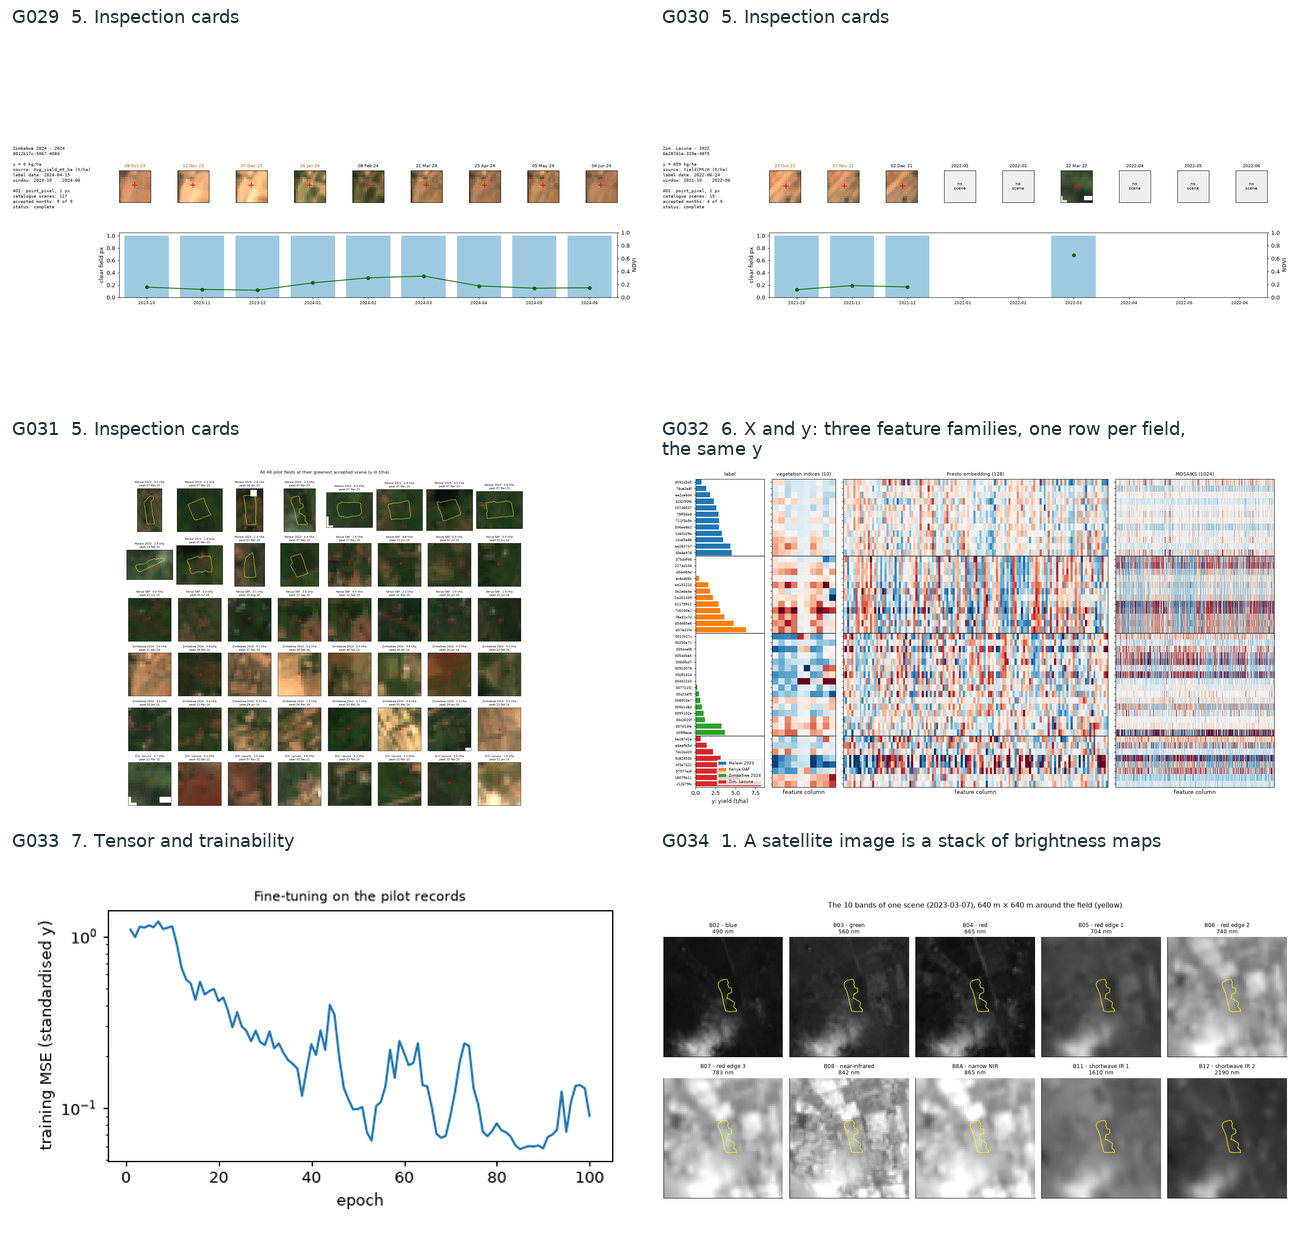

- **G029** A red cross locates one Zimbabwe 2024 record across nine monthly images. This example has a recorded zero yield. Blue bars count clear field pixels and the green line gives NDVI. [02_pilot48.ipynb · cell 13, output 4](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G030** A red cross locates one Lacuna 2022 observation on the available Sentinel-2 images. Gray tiles identify months without an accepted scene. The green NDVI line and clear-pixel bars use the available dates. [02_pilot48.ipynb · cell 13, output 5](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G031** Each tile shows a pilot field in its greenest accepted scene and gives its recorded yield in t/ha. Yellow boundaries identify polygon observations and red crosses mark point observations. [02_pilot48.ipynb · cell 14, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G032** Each row represents the same pilot field across three feature families. The bar at left gives measured yield. Blue and red cells show feature values below and above their column means after standardization. [02_pilot48.ipynb · cell 18, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G033** The curve tracks training mean squared error over 100 fine-tuning epochs on the usable pilot fields. Yield was standardized before fitting. The logarithmic error axis makes changes late in training visible. [02_pilot48.ipynb · cell 22, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/02_pilot48.ipynb)

- **G034** Ten panels show a 640 m square around the same Malawi field in the same satellite acquisition. The yellow line marks the field. Lighter grayscale values indicate stronger reflectance in the band named above each panel. [03_how_the_data_works.ipynb · cell 4, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

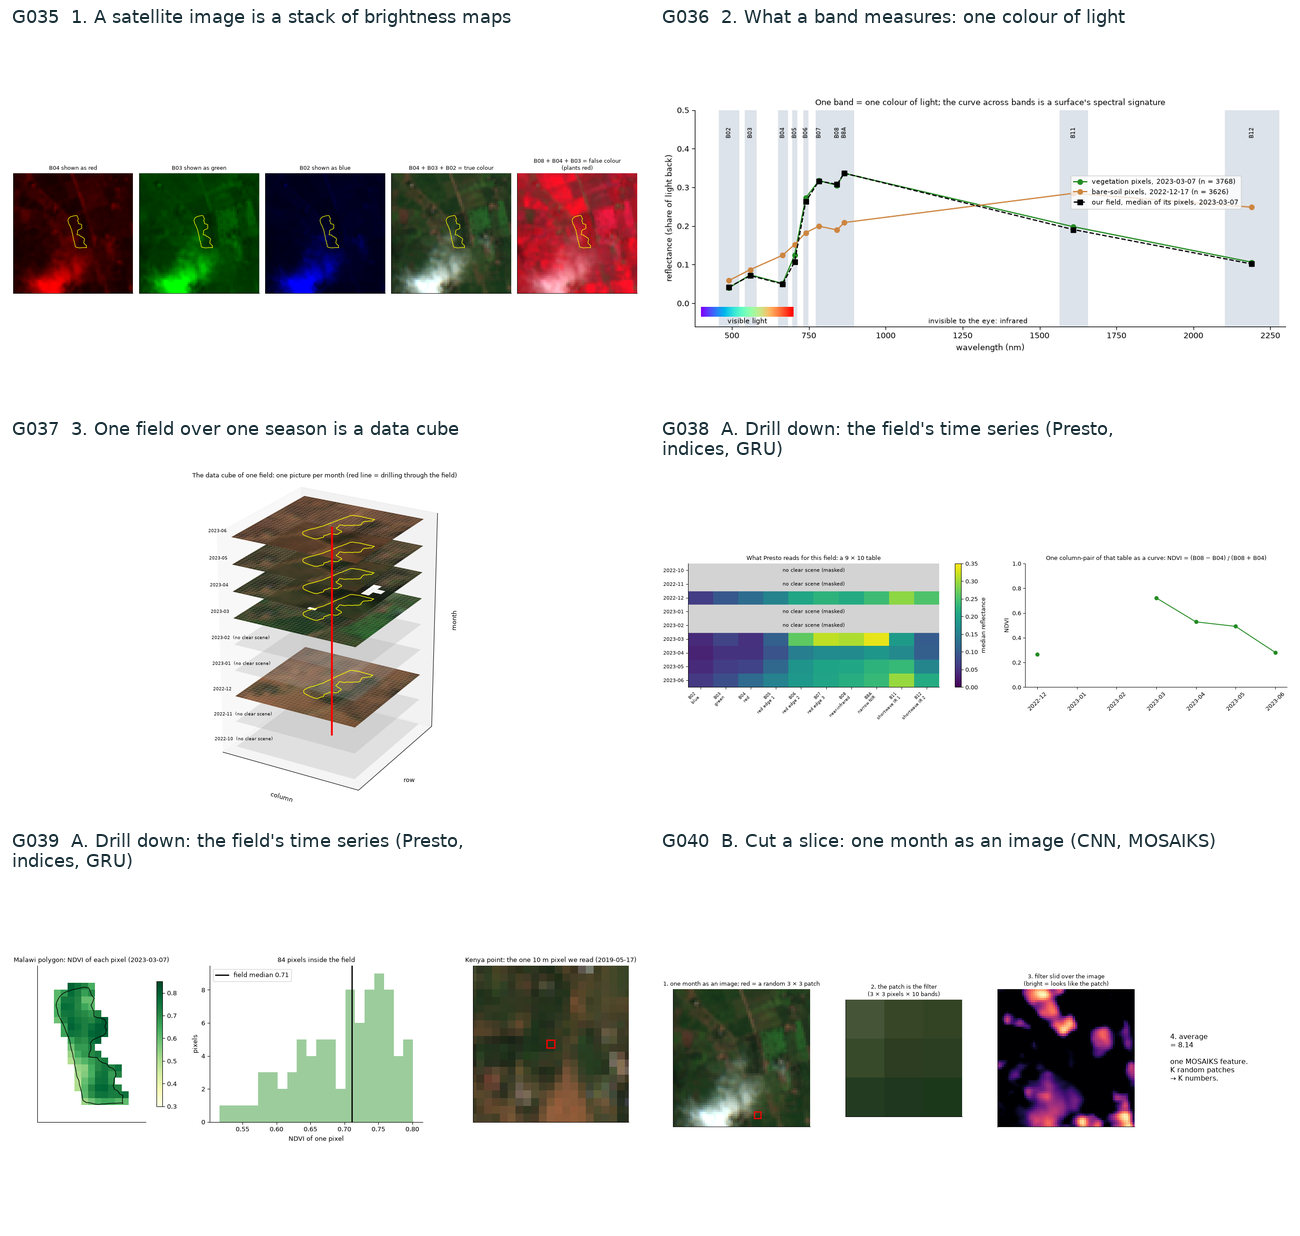

- **G035** The first three images display individual red, green and blue bands of the Malawi field. The last two combine them into visible color and a near-infrared composite, where vegetation appears red. Yellow outlines mark the same field. [03_how_the_data_works.ipynb · cell 6, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G036** Wavelength runs from visible light to infrared. Green and brown curves summarize reflectance for pixels classified as vegetation and bare soil in the chosen scenes. The dashed black line is the example field’s median, and shaded strips mark the Sentinel-2 bands. [03_how_the_data_works.ipynb · cell 8, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G037** Each layer is a monthly satellite view of one Malawi field. Yellow traces its boundary. The red vertical line marks one pixel through time, and translucent gray layers identify months without a clear scene. [03_how_the_data_works.ipynb · cell 10, output 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G038** The left heatmap shows monthly median reflectance by band for one field, with gray rows marking gaps. At right, the red and near-infrared band values from that table are combined into an NDVI time series. [03_how_the_data_works.ipynb · cell 12, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G039** Green shades at left show pixel-level NDVI within a surveyed Malawi field. The center histogram gives the distribution for its interior pixels. At right a red square marks the single 10 m pixel used for a Kenya point observation. [03_how_the_data_works.ipynb · cell 14, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G040** In a Malawi satellite chip, the red square picks a 3 × 3 pixel filter. The response map lights up where other patches produce a large filter response. The mean response produces one illustrative MOSAIKS feature. [03_how_the_data_works.ipynb · cell 16, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

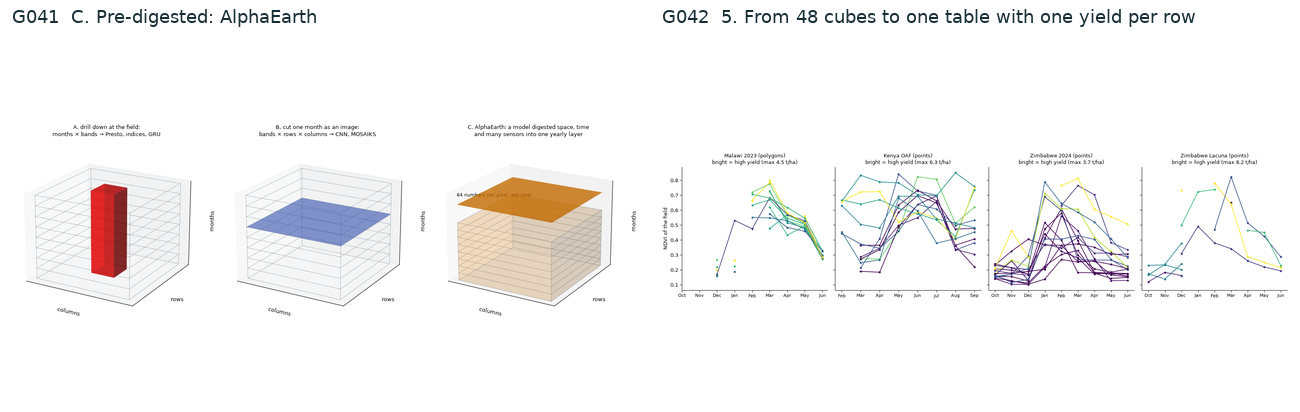

- **G041** These schematic cubes illustrate three ways to use an image sequence. The red column follows one location through time, the blue plane samples a whole image at one time, and the orange panel represents an annual embedding layer. [03_how_the_data_works.ipynb · cell 18, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

- **G042** Each line tracks monthly field NDVI for one observation in the archived pilot. Within each cohort, brighter colors mean higher measured yield relative to that cohort’s maximum. Missing monthly observations leave gaps in the curves. [03_how_the_data_works.ipynb · cell 20, output 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/notebooks/03_how_the_data_works.ipynb)

In [13]:
show_gallery(gallery, "Archived notebook figures")

### Archived project diagrams

3 unique previews · 3 figures referenced in this section.

**G070 · From field observations to held-out yield estimates**

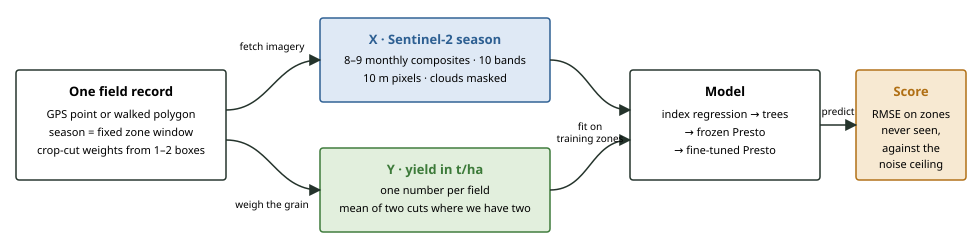

**G071 · From one field to satellite inputs and a yield label**

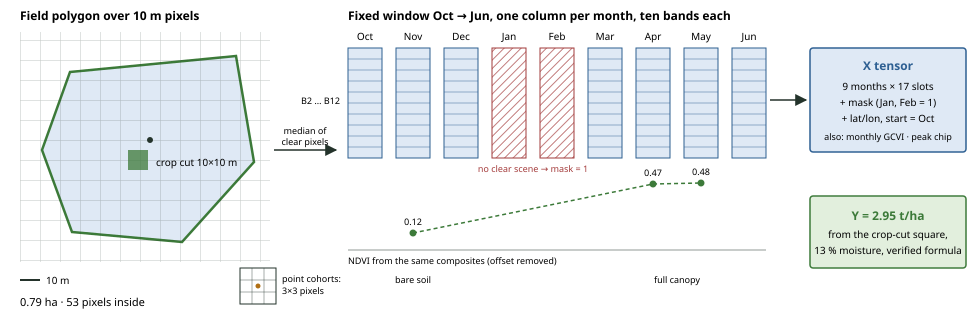

**G072 · Decision gates in the original experiment plan**

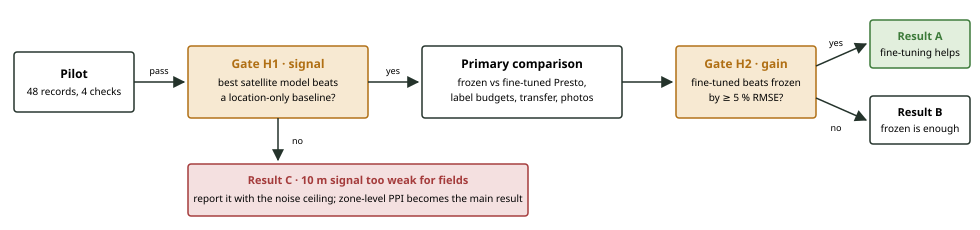

- **G070** This archived workflow traces ground observations and imagery through the prediction pipeline to held-out scoring. The arrows show dependencies among processing steps. [project_map_2026-10-25.html · diagram 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

- **G071** This archived sketch traces how the satellite observations for a field form a feature vector and how its crop-cut measurement supplies the yield target. [project_map_2026-10-25.html · diagram 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

- **G072** This archived decision diagram shows how pilot performance against a location baseline and the gain from fine-tuning determined the planned next experiment. [project_map_2026-10-25.html · diagram 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/_parked/docs/archive/project_map_2026-10-25.html)

In [14]:
show_gallery(gallery, "Archived project diagrams")

### Provider documentation figures

12 unique previews · 12 figures referenced in this section.

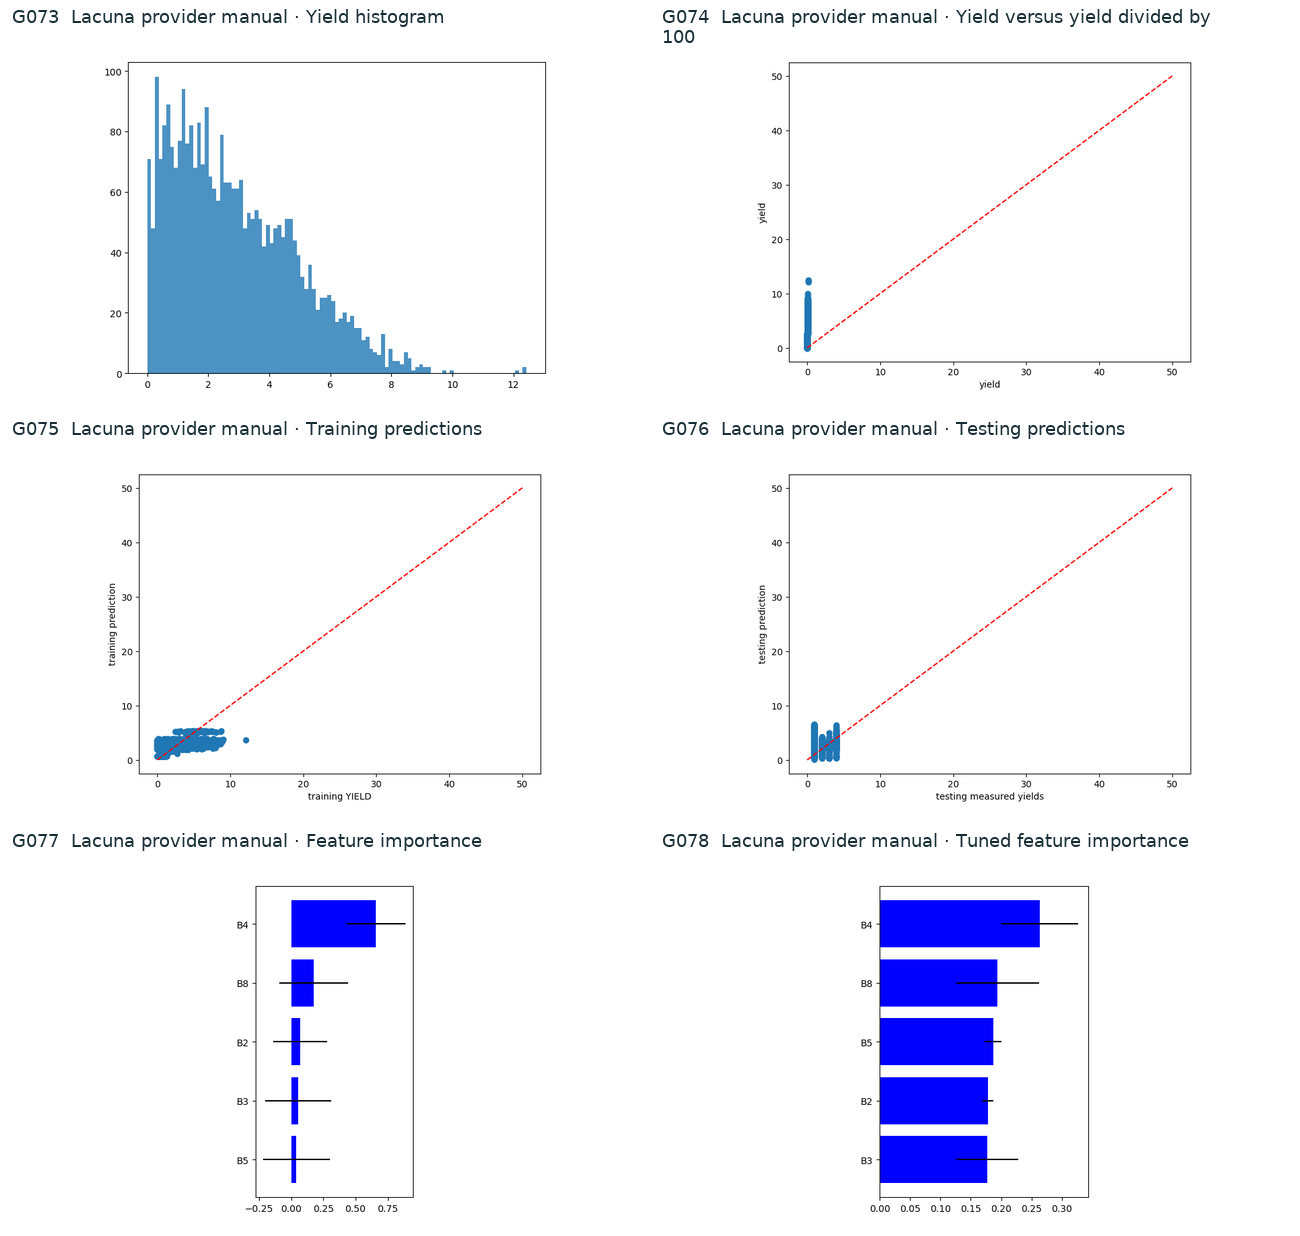

- **G073** The provider manual counts crop-cut records in narrow bins of measured yield (Mg/ha). Most measurements appear near the lower end, with a long tail extending beyond 10 Mg/ha. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 1](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G074** The manual plots reported yield divided by 100 horizontally against the same unscaled yield vertically. The red dashed line marks equal axis values. Dividing the horizontal values by 100 concentrates the points near zero on that axis. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 2](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G075** Each point compares measured yield and a random-forest training prediction from the provider manual. The dashed diagonal marks equality. Points below it show training records for which the model predicted a lower yield than the crop cut. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 3](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 6](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G076** The provider manual plots measured test-set yield horizontally against its random-forest prediction vertically. Vertical distance from the dashed equality line gives each record’s prediction error. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 4](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 7](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G077** Horizontal bars rank five multispectral bands by importance in the provider’s yield regression forest. The red reflectance band B4 has the largest bar, followed by the near-infrared band B8. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 5](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 8](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G078** After the provider tunes its yield regression forest, the bars give the fitted importance for each spectral band. B4 remains the highest-ranked band, and the other four have more similar importance values. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 6](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 9](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

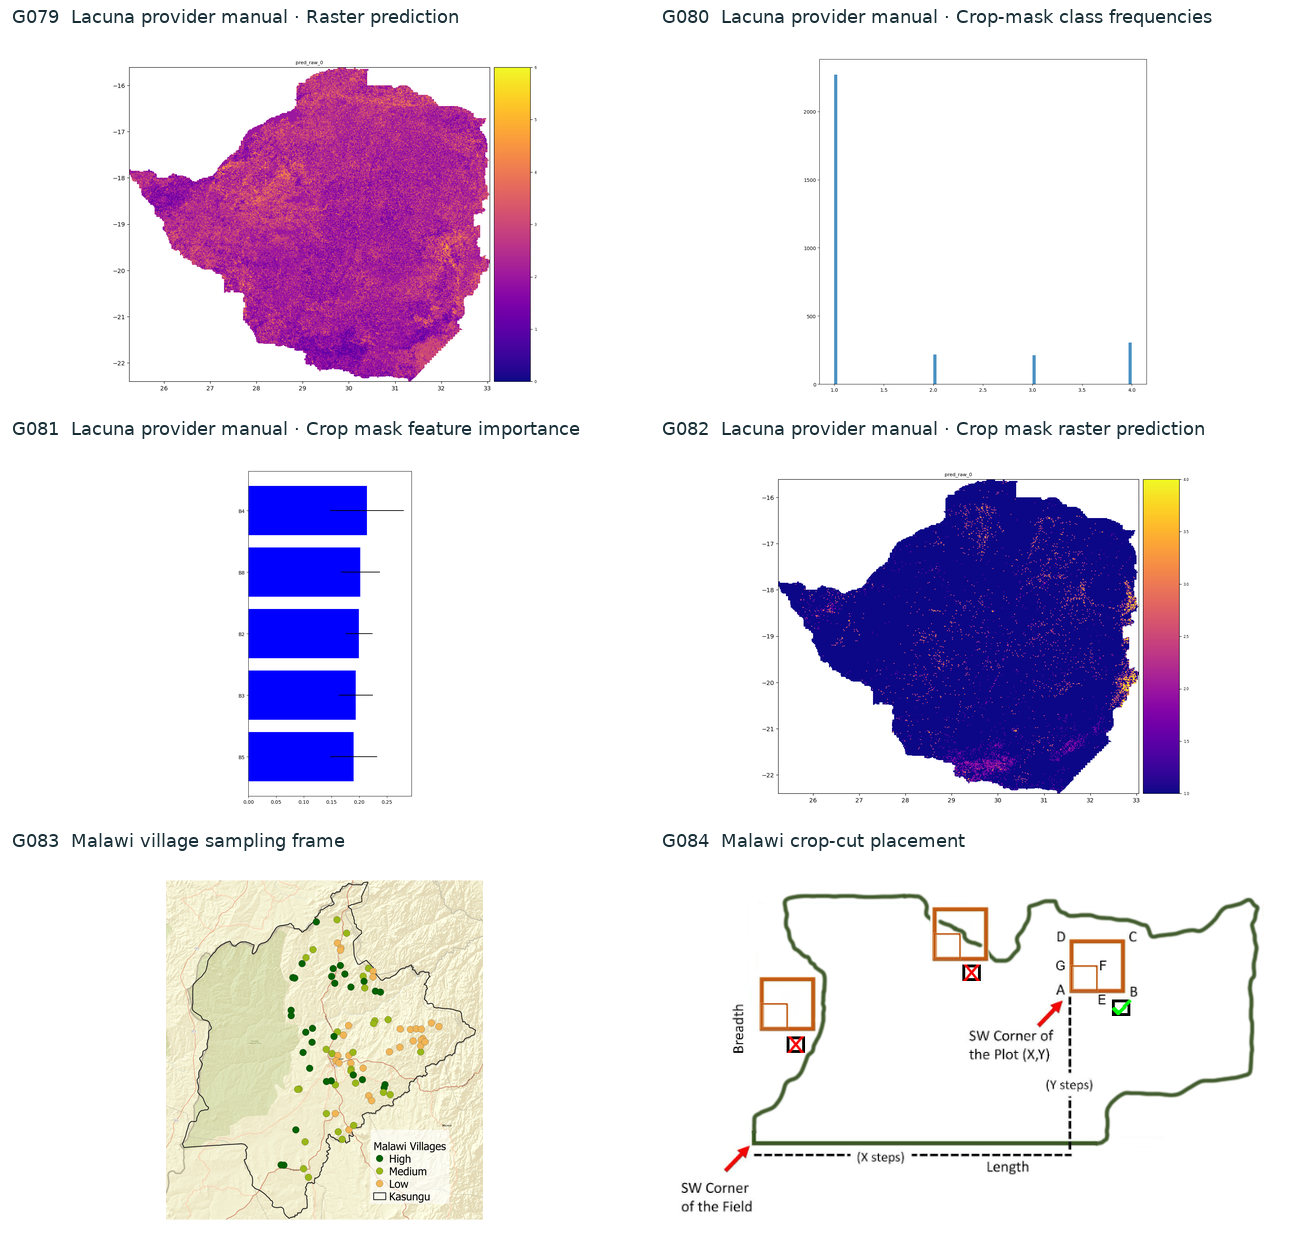

- **G079** The Lacuna provider’s random-forest example predicts yield across Zimbabwe from multispectral raster inputs. Dark purple through yellow denotes lower through higher model output on the published 0–6 scale. White lies outside the displayed raster footprint. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 7](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 11](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G080** This histogram counts the four categorical codes used to train the provider’s crop-mask classifier. Class 1 is the most frequent. The manual stores these class labels in a column named yield. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 8](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 12](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G081** Bars rank five multispectral bands by importance in the provider’s crop-mask classifier. B4 has the longest bar, though the displayed importances are close across all five bands. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 9](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 15](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G082** The Lacuna provider’s classifier assigns a crop class to each pixel in this Zimbabwe map. Purple, orange and yellow encode the published class codes 1–4. [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual.slides.html · HTML figure 10](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual.slides.html) · [Yield_forecasting _and_Crop_Mask_LACUNA_Technical_Manual_2.pdf · page 16](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/zimbabwe/Yield_forecasting%20_and_Crop_Mask_LACUNA_Technical_Manual_2.pdf)

- **G083** Dots locate villages in the Kasungu district sampling frame in Malawi. Dark green, light green and orange identify high, medium and low peak NDVI classes used for sample selection. The black outline marks the district. [nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx · word/media/image1.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/malawi/nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx)

- **G084** The Malawi fieldwork diagram locates the nested 5 × 5 m and 10 × 10 m crop cuts using distances from a field’s southwest corner. Crosses flag rejected placements and the check marks the accepted placement. [nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx · word/media/image2.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/data/raw/malawi/nasa-harvest-fao-crop-cut-campaign-2023-sampling-frame-methodology.docx)

In [15]:
show_gallery(gallery, "Provider documentation figures")

### Reconstructed v2 report figures

4 unique previews · 4 figures referenced in this section.

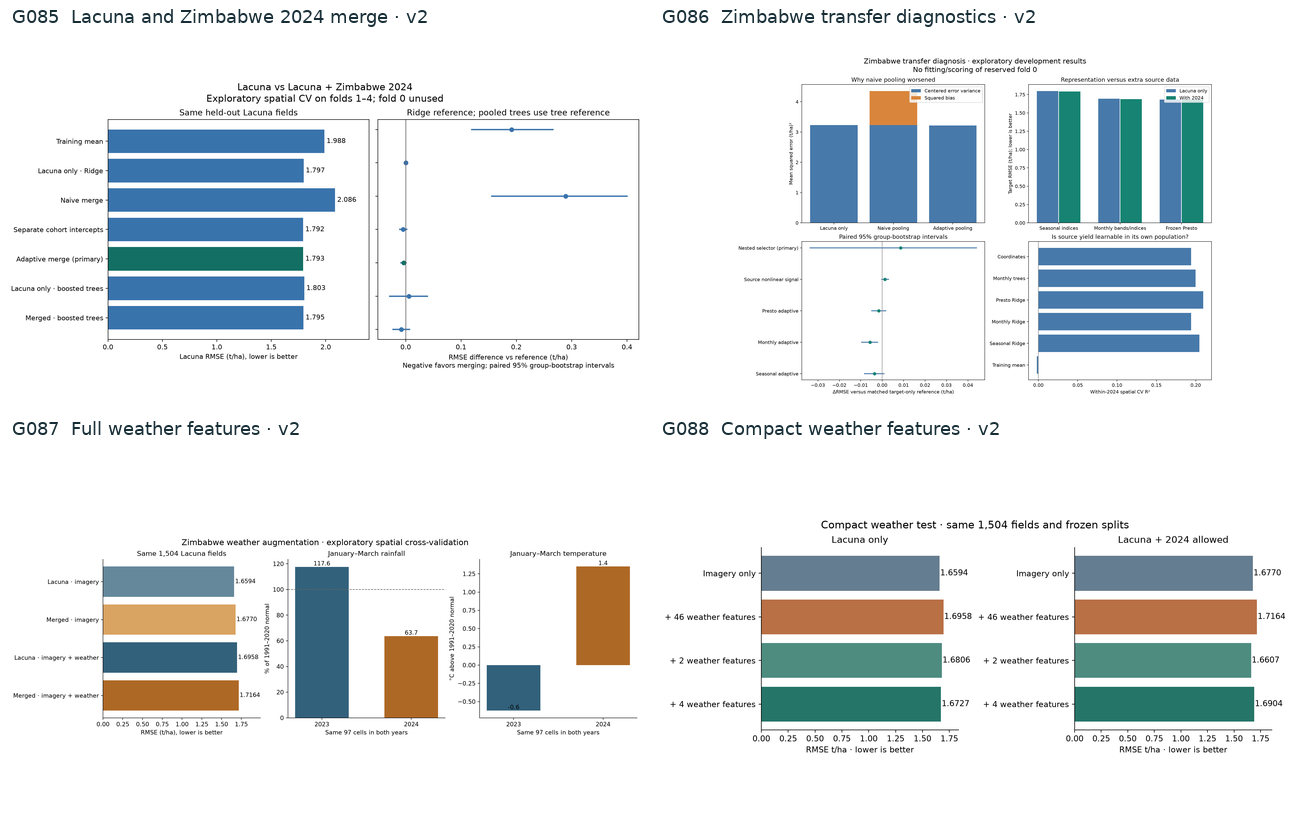

- **G085** On the v2 eligible training rows, the left bars compare model RMSE on the same Lacuna holdout fields. The right dots give RMSE differences from the corresponding Lacuna-only reference, with paired 95% spatial-group bootstrap intervals. [RESULTS.md · report link comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/merge_v2/merge/RESULTS.md)

- **G086** The v2 panels compare squared bias and centered error variance, predictions using different feature families, and paired changes in RMSE when 2024 records enter training. The final panel reports R² within the eligible 2024 source population. [RESULTS.md · report link diagnosis.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/merge_v2/diagnosis/RESULTS.md)

- **G087** The left panel compares v2 Lacuna-only and merged tree-model errors with imagery alone and with weather. The two right panels place the 2023 and 2024 harvests in context using January–March rainfall and temperature over the same 97 weather cells. [RESULTS.md · report link weather_comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/weather_v2/full/RESULTS.md)

- **G088** The two v2 panels compare imagery-only, full-weather and compact-weather tree models trained with Lacuna alone or with eligible 2024 observations. Shorter bars mean smaller RMSE on the same 1,504 evaluation fields. [RESULTS.md · report link compact_weather_comparison.png](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/results/weather_v2/compact/RESULTS.md)

In [16]:
show_gallery(gallery, "Reconstructed v2 report figures")

### Reconstructed Presto diagnostics

18 unique previews · 18 figures referenced in this section.

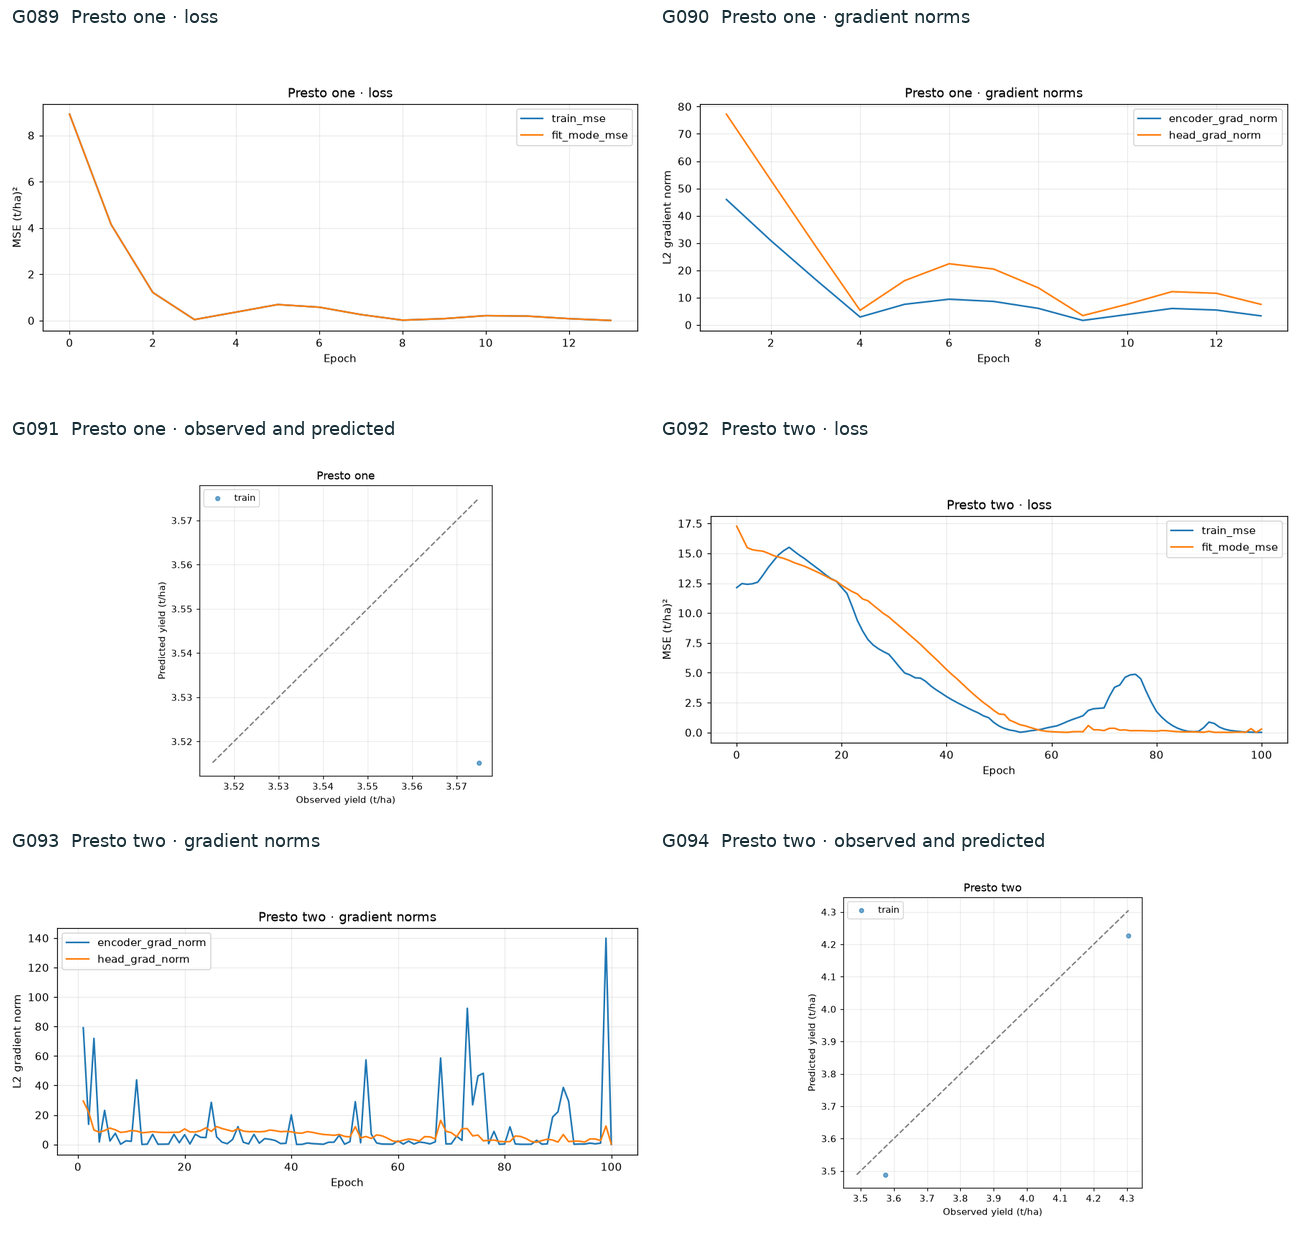

- **G089** For the single-field memorization check, the curves show mean squared error across epochs using evaluation mode and fitting mode. Both reach about 0.0036 (t/ha)² by epoch 13. [history.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/history.csv)

- **G090** The two lines trace the encoder and prediction-head gradient norms during the single-field check. A positive encoder norm shows that the training signal reaches the satellite encoder during backpropagation. [history.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/history.csv)

- **G091** The one point pairs the training field’s observed yield of 3.58 t/ha with its final Presto estimate of 3.52 t/ha. The dashed equality line shows the small underprediction. [predictions.csv · one](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/one/predictions.csv)

- **G092** The two-field check tracks fitting-mode and evaluation-mode mean squared error separately across 100 epochs. Their separation reflects the different batch-normalization statistics used in these modes. [history.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/history.csv)

- **G093** Encoder and prediction-head gradient norms are plotted by epoch during the two-field training check. Both series show when updates carry gradient signal through the model. [history.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/history.csv)

- **G094** The two points pair observed training yields of 3.58 and 4.30 t/ha with estimates of 3.49 and 4.23 t/ha. The diagonal gives exact agreement for this two-field memorization check. [predictions.csv · two](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/two/predictions.csv)

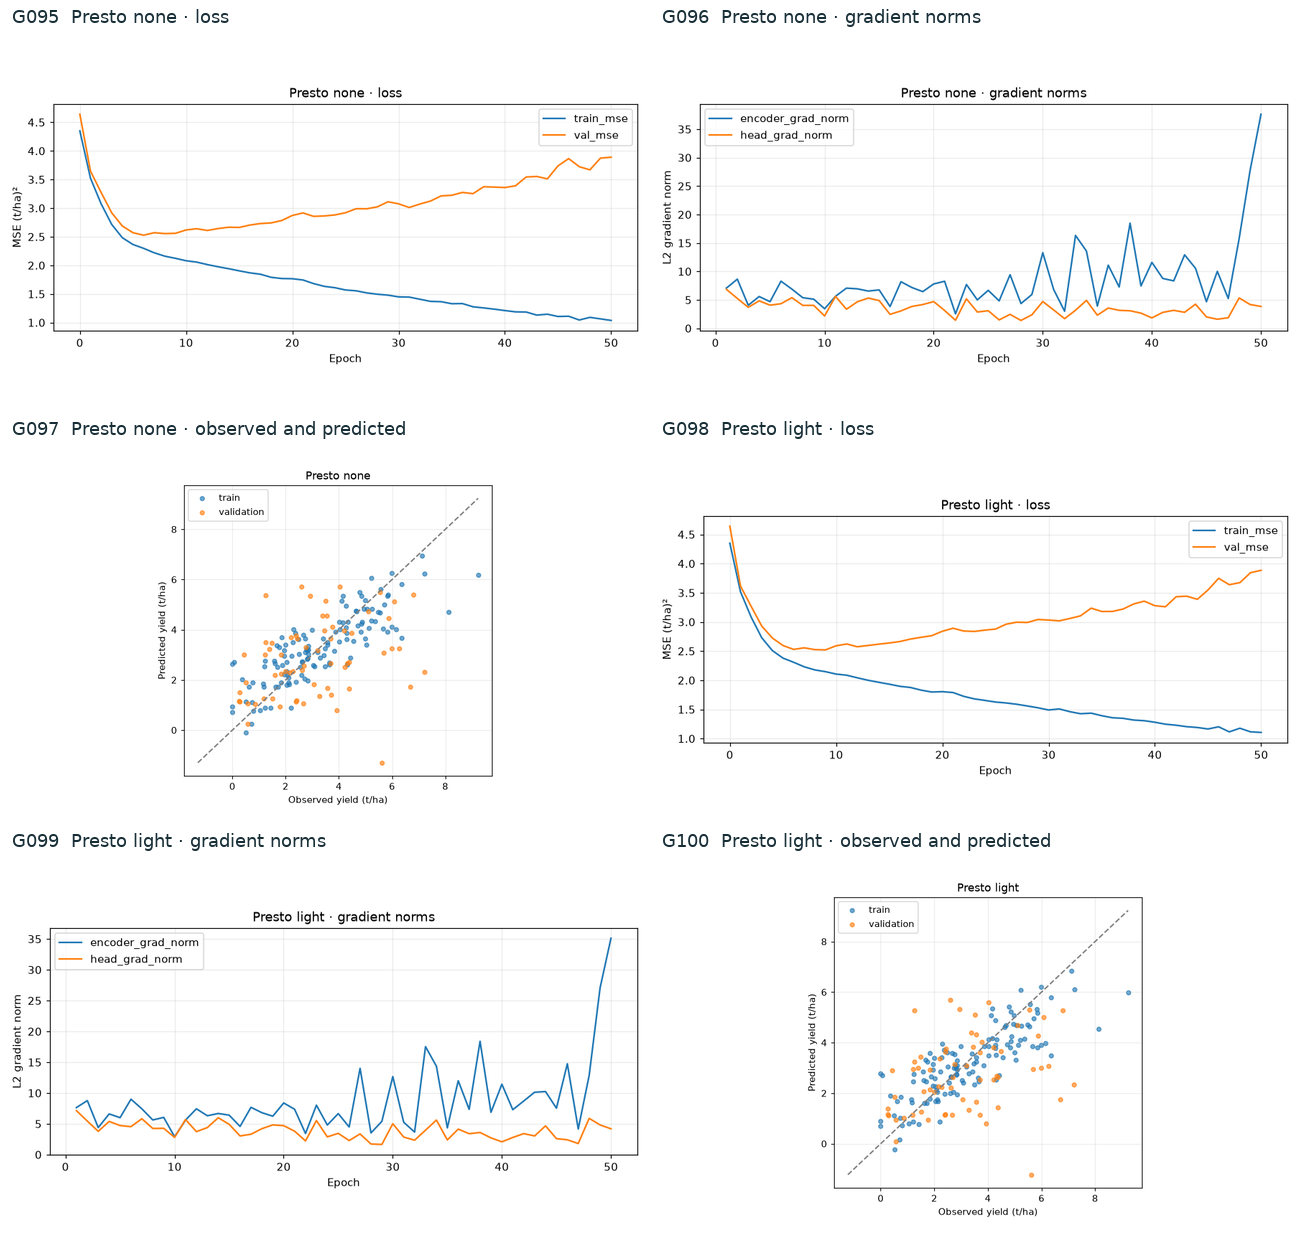

- **G095** The zero-regularization run compares training and validation mean squared error through 50 epochs. Validation error reaches its minimum at epoch 6 and finishes at 3.89 (t/ha)² while final training error is 1.04 (t/ha)². [history.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/history.csv)

- **G096** Lines show encoder and prediction-head gradient norms at each epoch in the zero-regularization run. Their median norms are 7.1 and 3.3, respectively. Peaks mark larger recorded gradients. [history.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/history.csv)

- **G097** For the zero-regularization run, colors separate 128 training fields and 64 validation fields. Each dot pairs measured and predicted yield. Validation estimates span -1.30 to 5.71 t/ha, and the diagonal marks exact agreement. [predictions.csv · none](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/none/predictions.csv)

- **G098** The light-regularization run compares training and validation mean squared error through 50 epochs. Validation error reaches its minimum at epoch 9 and finishes at 3.89 (t/ha)² while final training error is 1.11 (t/ha)². [history.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/history.csv)

- **G099** Lines show encoder and prediction-head gradient norms at each epoch in the light-regularization run. Their median norms are 7.3 and 3.8, respectively. Peaks mark larger recorded gradients. [history.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/history.csv)

- **G100** For the light-regularization run, colors separate 128 training fields and 64 validation fields. Each dot pairs measured and predicted yield. Validation estimates span -1.23 to 5.68 t/ha, and the diagonal marks exact agreement. [predictions.csv · light](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/light/predictions.csv)

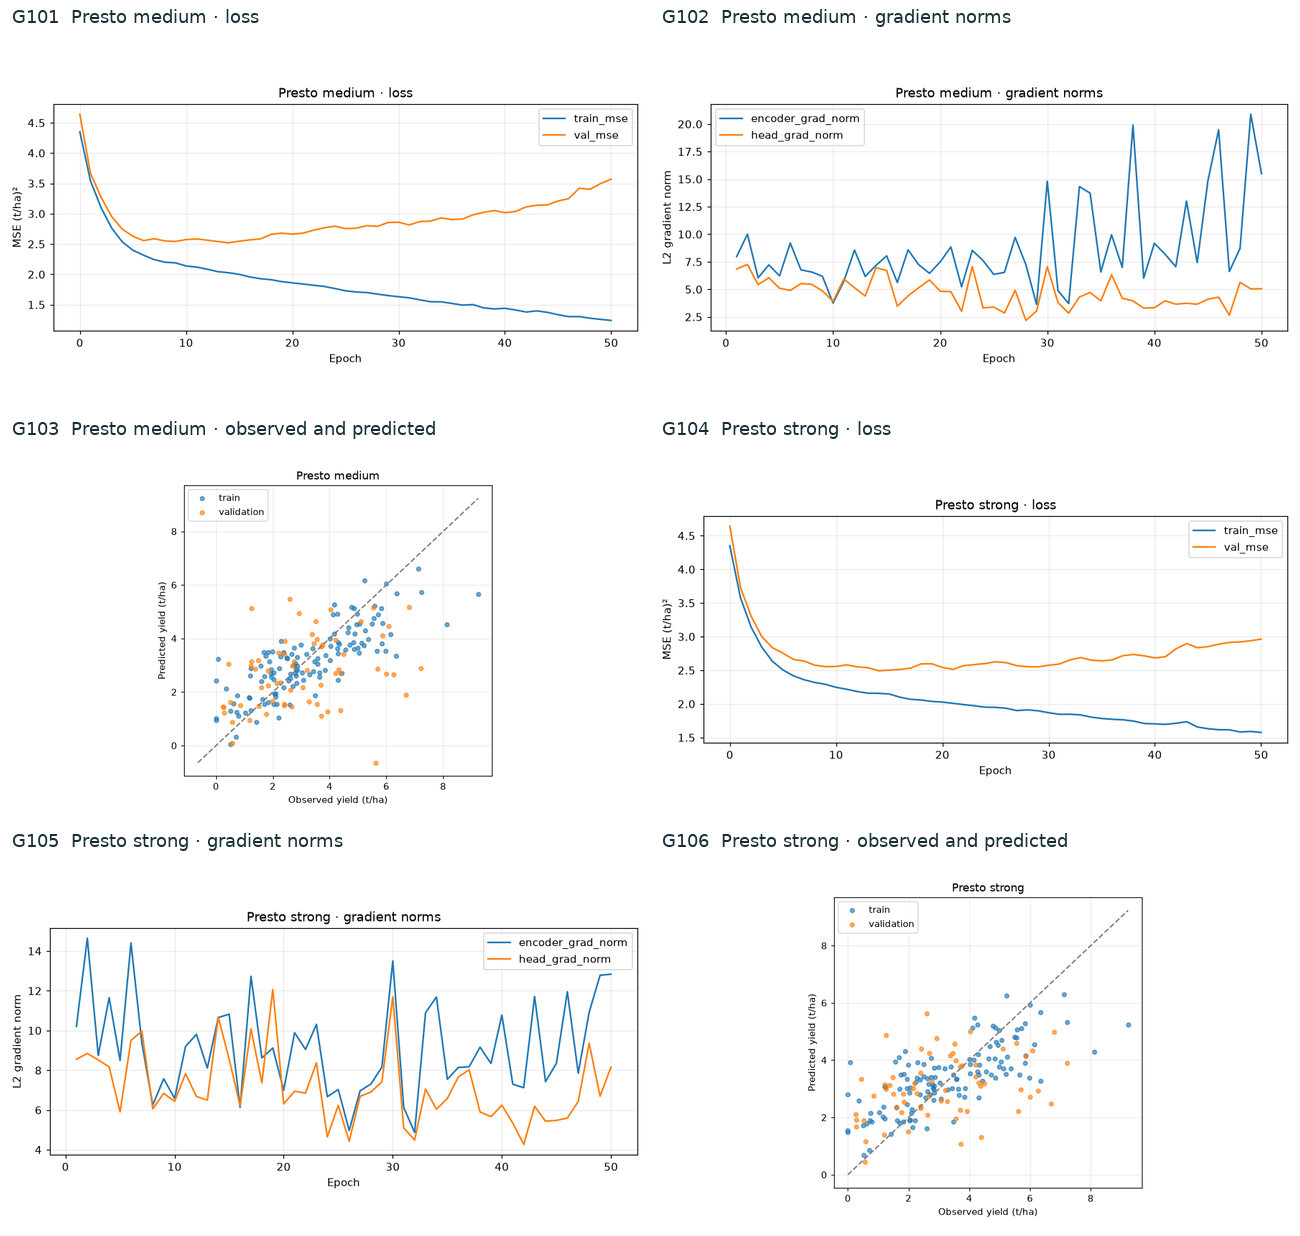

- **G101** The medium-regularization run compares training and validation mean squared error through 50 epochs. Validation error reaches its minimum at epoch 14 and finishes at 3.57 (t/ha)² while final training error is 1.24 (t/ha)². [history.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/history.csv)

- **G102** Lines show encoder and prediction-head gradient norms at each epoch in the medium-regularization run. Their median norms are 7.3 and 4.6, respectively. Peaks mark larger recorded gradients. [history.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/history.csv)

- **G103** For the medium-regularization run, colors separate 128 training fields and 64 validation fields. Each dot pairs measured and predicted yield. Validation estimates span -0.64 to 5.48 t/ha, and the diagonal marks exact agreement. [predictions.csv · medium](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/medium/predictions.csv)

- **G104** The strong-regularization run compares training and validation mean squared error through 50 epochs. Validation error reaches its minimum at epoch 14 and finishes at 2.96 (t/ha)² while final training error is 1.58 (t/ha)². [history.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/history.csv)

- **G105** Lines show encoder and prediction-head gradient norms at each epoch in the strong-regularization run. Their median norms are 8.7 and 6.7, respectively. Peaks mark larger recorded gradients. [history.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/history.csv)

- **G106** For the strong-regularization run, colors separate 128 training fields and 64 validation fields. Each dot pairs measured and predicted yield. Validation estimates span 0.44 to 5.62 t/ha, and the diagonal marks exact agreement. [predictions.csv · strong](https://github.com/FelixYu120/DSC-291-Final-Project/blob/8de629aba00ea3cda483fc8f113db38fe8961869/experiments/presto_debug/runs/latest/strong/predictions.csv)

In [17]:
show_gallery(gallery, "Reconstructed Presto diagnostics")

In [18]:
# Enter an ID from the gallery to display its full-resolution image.
figure_id = ""
if figure_id:
    show_figure(gallery, figure_id.upper())